# EDA de contratación directa inspirado en Fedesarrollo / BID

**Réplica analítica adaptada a SECOP II: datos reales locales, resultados dentro del notebook.**

Fuente metodológica: Zuleta, Ospina y Caro, *Índice de riesgo de corrupción en el sistema de compra pública colombiano a partir de una metodología desarrollada por el Instituto Mexicano para la Competitividad*, BID, 2019. Documento local: [FEDESARROLLO_CPBD.pdf](file:///C:/Users/luna3/Downloads/FEDESARROLLO_CPBD.pdf), 67 páginas. Las referencias siguientes son páginas del PDF.

El estudio combina fuentes y examina 2014–junio de 2018; este proyecto tiene SECOP II desde 2017. Se replican preguntas, agregaciones y comparaciones, **no los valores publicados ni el índice IMCO de 32 indicadores**. No se trasladan sus etiquetas de corrupción a los contratos actuales. El IRCD conserva exclusivamente C/R/A y no se modifica desde este EDA.

**Diferencia decisiva:** el estudio excluye ciertas prestaciones personales superiores a seis meses (pp. 15–16). Nuestro caso prioriza esos servicios: se conservan y se mide la sensibilidad de esa decisión. No se equipara duración larga a servicio personal, ni se presume persona jurídica a partir de NIT.

**Dos universos:** (1) contratos de todas las modalidades para denominadores y contexto; (2) contratación directa exacta para el caso de control. Calcular la participación de directa usando solo Gold directo produciría un 100% artificial. La variante «directa con ofertas» se muestra por separado.

Las tablas son censos del snapshot salvo los scatterplots, cuya muestra reproducible se declara. Las tablas intermedias existen solo en memoria/temporales de DuckDB; no se exportan resultados ni se modifica Bronze, Silver, Gold o PostgreSQL.

**Advertencia empírica:** hay importes extremos ya presentes en Bronze que dominan los totales. La sección 2b muestra procedencia y sensibilidad. Los montos son reportados, no gasto verificado; validez numérica no acredita corrección económica.

## Mapa de réplica y diferencias

| Elemento del estudio | Réplica en este notebook | Diferencia / límite |
| --- | --- | --- |
| Tabla 2, pp. 15–16: depuración | Embudo auditable y sensibilidad | Se conservan servicios; falta fecha original de cargue |
| Tabla 1 y Figura 1, pp. 10–11 | Contratos e importes por año/nivel | Solo SECOP II; COP nominales; último año parcial |
| Figura 2, p. 13; Tabla 14, p. 58 | Modalidad, tipo y categoría | Tipos de SECOP II, sin inventar las siete categorías de SECOP I |
| Tabla 5 y Figura 4, pp. 30–33 | Composición y distribución por nivel/centralización | Sin categorías municipales 1–6 ni maestro de entidades |
| Figuras 6–8 y Tabla 8, pp. 38–43 | Participación de directa y especial, evolución y enero | Son descripciones; no alertas adicionales ni conclusiones legales |
| Tabla 9, pp. 44–45 | Cuatro mayores proveedores por año | Alias para no exponer documentos personales |
| Tabla 10, p. 46 | HHI por conteo y monto; CR4 | Fracción 0–1 explícita; no transformación del IMCO a riesgo 0–100 |
| Figura 11 / Tabla 13, pp. 55–57 | Comparación por deciles de gasto | Deciles de gasto observado; no de presupuesto ni de riesgo |
| Tabla 15, p. 59 | Concentración por tipo y categorías | No se reconstruye el índice agregado de 32 indicadores |
| Transparencia / sanciones / oferentes | Matriz de no replicabilidad | No hay base documental/sanciones; fuera del índice C/R/A |
| Recurrencia y valores comparables | Extensión explícita para el caso actual | No se atribuyen estas fórmulas nuevas a Fedesarrollo |

**Hipótesis:** H1: directa domina el número más que el monto; H2: concentración cambia al medir dinero frente a conteos; H3: parte de la concentración aparente se asocia a escala pequeña; H4: enero concentra contratación; H5: recurrencia y concentración comparten información; H6: mezclar tipos y duraciones distorsiona comparaciones monetarias.

In [1]:
from pathlib import Path
import json, tempfile, hashlib, time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT=Path.cwd()
if not (ROOT/'secop_pipeline').exists(): ROOT=ROOT.parent
assert (ROOT/'secop_pipeline').exists(), 'Ejecute desde la raíz o notebooks del proyecto'
manifest=json.loads((ROOT/'salida/manifest_extraccion.json').read_text(encoding='utf-8'))
INICIO=pd.Timestamp(manifest['start_date'])
CORTE=pd.Timestamp(manifest['cutoff_date'])
ANIO=min(2025, CORTE.year if CORTE.month==12 and CORTE.day==31 else CORTE.year-1)
MIN_CONTRATOS=30
MUESTRA_SCATTER=15000
MEMORIA='2GB'
scratch=tempfile.TemporaryDirectory(prefix='secop-eda-')
con=duckdb.connect()
con.execute(f"SET memory_limit='{MEMORIA}'")
con.execute('SET threads=2')
con.execute('SET preserve_insertion_order=false')
con.execute('SET temp_directory=?',[scratch.name])
def q(sql,params=None): return con.execute(sql,params or []).df()
def sql(s): con.execute(s)
def L(s): return "'"+str(s).replace("'","''")+"'"
def conclusion(s): display(Markdown('**Conclusión de esta ejecución.** '+s))
def fmt(v): return f'{v:,.0f}'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':.18,'font.size':10})
plt.rcParams['axes.prop_cycle']=plt.cycler(color=['#235789','#e99b28','#429980','#ad557a','#777777'])
pd.set_option('display.max_columns',18)
pd.set_option('display.max_rows',35)
pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
display(pd.DataFrame([{'cobertura_inicio':INICIO.date(),'corte':CORTE.date(),
    'año_comparación':ANIO,'fuente':'Silver contratos SECOP II','mínimo_por_entidad':MIN_CONTRATOS,
    'memoria_DuckDB':MEMORIA,'unidades':'COP nominales; billón = 10^12 COP',
    'fecha_ejecución_UTC':pd.Timestamp.now(tz='UTC').isoformat()}]))
files=sorted((ROOT/'data/silver/contratos').glob('*.parquet'))
assert files,'No existen contratos Silver'
estado_archivos=[(str(p),p.stat().st_size,p.stat().st_mtime_ns) for p in files]
huella_inventario=hashlib.sha256(json.dumps(estado_archivos).encode()).hexdigest()
print('Huella de inventario (rutas/tamaños/mtime; NO hash de contenido):',huella_inventario)
con.from_parquet([str(p) for p in files],union_by_name=True).create_view('fuente')
columnas=set(q('DESCRIBE fuente').column_name)
opcionales=['tipodocproveedor','justificacion_modalidad_de','objeto_del_contrato','urlproceso']
display(pd.DataFrame({'campo':opcionales,'disponible':[c in columnas for c in opcionales]}))

,cobertura_inicio,corte,año_comparación,fuente,mínimo_por_entidad,memoria_DuckDB,unidades,fecha_ejecución_UTC
0,2017-01-01,2026-09-21,2025,Silver contratos SECOP II,30,2GB,COP nominales; billón = 10^12 COP,2026-10-08T15:47:22.836699+00:00


Huella de inventario (rutas/tamaños/mtime; NO hash de contenido): 40b6d049f8bca4139f0bc31dad202855f0bb582e4edf4c54b2f62ee25318d09a


,campo,disponible
0,tipodocproveedor,True
1,justificacion_modalidad_de,True
2,objeto_del_contrato,True
3,urlproceso,True


## 1. Depuración y unidad contractual

**Referencia:** Tabla 2, pp. 15–16.

**Por qué:** Las repeticiones de un mismo contrato inflan montos, concentración y recurrencia. La primera fila no equivale a la versión correcta.

**Qué y cómo:** Se conserva la última actualización inequívoca. Si hay versiones contradictorias empatadas o versiones sin fecha que impiden ordenarlas, el ID se aparta. Se comparan todas las columnas leídas con una huella MD5 de fila para igualdad técnica; no es una medida de riesgo. Los registros descartados se cuentan por motivo, sin borrarlos de Silver.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

In [2]:
sql("CREATE MACRO norm(x) AS nullif(lower(strip_accents(trim(cast(x AS VARCHAR)))), '')")
sql("CREATE MACRO ident(x) AS CASE WHEN norm(x) IN ('no definido','no informado','no aplica','sin dato','0','-','.') THEN NULL ELSE nullif(regexp_replace(upper(trim(cast(x AS VARCHAR))),'[.[:space:]-]','','g'),'') END")
def optional(name): return name if name in columnas else 'NULL::VARCHAR'
sql(f'''CREATE TEMP TABLE entrada AS SELECT
 nullif(upper(trim(id_contrato)),'') id_contrato,ident(nit_entidad) entidad_id,
 coalesce('SECOP:'||ident(codigo_proveedor),
   CASE WHEN norm({optional('tipodocproveedor')}) IS NOT NULL THEN norm({optional('tipodocproveedor')})||':'||ident(documento_proveedor) END) proveedor_id,
 nombre_entidad,norm(orden) nivel,norm(entidad_centralizada) centralizacion,
 norm(departamento) departamento,norm(tipo_de_contrato) tipo,
 norm(modalidad_de_contratacion) modalidad,norm(codigo_de_categoria_principal) categoria,
 norm({optional('justificacion_modalidad_de')}) causal,
 CASE WHEN norm({optional('tipodocproveedor')}) IN ('cc','ce','cedula de ciudadania','cedula de extranjeria','pasaporte') THEN 'natural' ELSE 'indeterminado' END persona,
 fecha_de_firma::DATE firma,fecha_de_inicio_del_contrato::DATE inicio,fecha_de_fin_del_contrato::DATE fin,
 ultima_actualizacion,valor_del_contrato valor,
 md5(to_json(f)) huella
 FROM fuente f''')
sql('''CREATE TEMP TABLE ordenadas AS SELECT *,
 dense_rank() OVER(PARTITION BY id_contrato ORDER BY ultima_actualizacion DESC NULLS LAST) r
 FROM entrada''')
sql('''CREATE TEMP TABLE versiones AS SELECT id_contrato,
 count(DISTINCT huella) FILTER(WHERE r=1) variantes_ultima,
 count(DISTINCT huella) variantes_total,
 count(*) FILTER(WHERE ultima_actualizacion IS NULL) sin_fecha FROM ordenadas GROUP BY 1''')
sql(f'''CREATE TEMP TABLE decisiones AS SELECT o.*,
 CASE WHEN o.id_contrato IS NULL THEN '01_sin_id'
 WHEN v.variantes_ultima>1 OR (v.variantes_total>1 AND v.sin_fecha>0) THEN '02_version_ambigua'
 WHEN r>1 THEN '03_version_anterior'
 WHEN row_number() OVER(PARTITION BY o.id_contrato,r ORDER BY huella)>1 THEN '04_repeticion_identica'
 WHEN firma IS NULL THEN '05_sin_firma_para_EDA_temporal'
 WHEN firma<DATE {L(INICIO.date())} OR firma>DATE {L(CORTE.date())} THEN '06_fuera_intervalo'
 ELSE '07_conservado' END destino
 FROM ordenadas o LEFT JOIN versiones v ON o.id_contrato IS NOT DISTINCT FROM v.id_contrato''')
embudo=q('SELECT destino,count(*) filas FROM decisiones GROUP BY 1 ORDER BY 1')
display(embudo)
sql('''CREATE TEMP TABLE contratos AS SELECT *,year(firma)::INTEGER anio,month(firma)::INTEGER mes,
 (fin-inicio+1)::INTEGER duracion_dias,
 CASE WHEN valor>=0 AND isfinite(valor) THEN valor END valor_valido,
 modalidad='contratacion directa' es_directa,
 modalidad IN ('contratacion regimen especial','contratacion regimen especial (con ofertas)') es_especial
 FROM decisiones WHERE destino='07_conservado' ''')
n_entrada=int(q('SELECT count(*) n FROM entrada').iloc[0,0])
n_contratos=int(q('SELECT count(*) n FROM contratos').iloc[0,0])
assert int(embudo.filas.sum())==n_entrada
assert int(q('SELECT count(DISTINCT id_contrato) n FROM contratos').iloc[0,0])==n_contratos
sql("CREATE VIEW directa AS SELECT * FROM contratos WHERE es_directa")
n_directa=int(q('SELECT count(*) n FROM directa').iloc[0,0])
conclusion(f'Entraron {fmt(n_entrada)} filas; quedan {fmt(n_contratos)} contratos únicos para el EDA temporal y {fmt(n_directa)} de modalidad directa exacta. '
           'Las exclusiones anteriores son de esta vista analítica: no se borraron datos. No se aplicaron las exclusiones de servicios del artículo.')
for table in ['entrada','ordenadas','versiones','decisiones']: sql('DROP TABLE '+table)

,destino,filas
0,04_repeticion_identica,295
1,07_conservado,5642436


**Conclusión de esta ejecución.** Entraron 5,642,731 filas; quedan 5,642,436 contratos únicos para el EDA temporal y 4,353,720 de modalidad directa exacta. Las exclusiones anteriores son de esta vista analítica: no se borraron datos. No se aplicaron las exclusiones de servicios del artículo.

## 2. Cobertura, faltantes y sensibilidad a la limpieza

**Referencia:** pp. 15–17; indicador 16, p. 26.

**Por qué:** Una aparente señal puede originarse en mala cobertura. El artículo verifica importes extremos con contratos; no debemos corregirlos sin documentos.

**Qué y cómo:** Se cuantifican nulos y valores inválidos. Se informa cuántos contratos de servicios tienen duración superior a seis meses calendario, pero no se presume que sean servicios personales o apoyo a la gestión. No se equipara última actualización a fecha original de publicación.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,contratos
contratos,5642436
sin_entidad,0
sin_proveedor,3
valor_ausente_o_no_finito,0
valor_negativo,0
valor_cero,41302
sin_causal,256
naturales_identificadas,4795951
sin_fechas_duracion,56777
duracion_no_positiva,776


,criterio,contratos,billones
0,Servicios de más de seis meses calendario (apr...,1788924,"137,801.564"
1,Operaciones de crédito público (tipo explícito),715,18.754


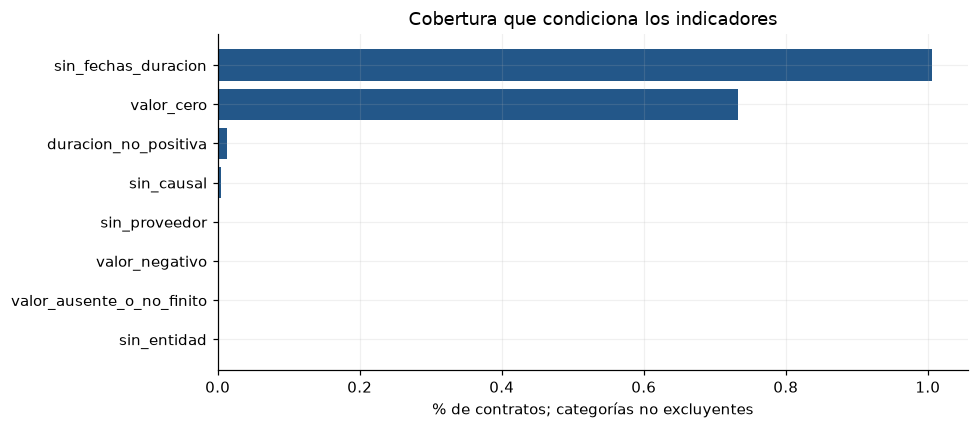

**Conclusión de esta ejecución.** Hay 256 contratos sin causal y 4,795,951 clasificados como persona natural. Ausencia de clasificación no equivale a persona jurídica. No es posible reproducir la depuración exacta por apoyo a la gestión, convenios interadministrativos o año de cargue sin campos/evidencia adicionales. Los importes siguen sujetos a la limpieza de la versión Silver existente.

In [3]:
calidad=q('''SELECT count(*) contratos,
 count(*) FILTER(WHERE entidad_id IS NULL) sin_entidad,
 count(*) FILTER(WHERE proveedor_id IS NULL) sin_proveedor,
 count(*) FILTER(WHERE valor IS NULL OR NOT isfinite(valor)) valor_ausente_o_no_finito,
 count(*) FILTER(WHERE valor<0) valor_negativo,count(*) FILTER(WHERE valor=0) valor_cero,
 count(*) FILTER(WHERE causal IS NULL) sin_causal,
 count(*) FILTER(WHERE persona='natural') naturales_identificadas,
 count(*) FILTER(WHERE inicio IS NULL OR fin IS NULL) sin_fechas_duracion,
 count(*) FILTER(WHERE duracion_dias<=0) duracion_no_positiva FROM contratos''')
display(calidad.T.rename(columns={0:'contratos'}))
sensibilidad=q('''SELECT 'Servicios de más de seis meses calendario (aproximación)' criterio,
 count(*) FILTER(WHERE tipo='prestacion de servicios' AND fin>inicio+INTERVAL 6 MONTHS) contratos,
 sum(valor_valido) FILTER(WHERE tipo='prestacion de servicios' AND fin>inicio+INTERVAL 6 MONTHS)/1e12 billones
 FROM contratos UNION ALL
 SELECT 'Operaciones de crédito público (tipo explícito)',count(*) FILTER(WHERE tipo='operaciones de credito publico'),
 sum(valor_valido) FILTER(WHERE tipo='operaciones de credito publico')/1e12 FROM contratos''')
display(sensibilidad)
fig,ax=plt.subplots(figsize=(9,4))
vals=calidad.iloc[0].drop(['contratos','naturales_identificadas']).sort_values()
ax.barh(vals.index,100*vals/calidad.iloc[0].contratos);ax.set_xlabel('% de contratos; categorías no excluyentes')
ax.set_title('Cobertura que condiciona los indicadores');plt.tight_layout();plt.show()
conclusion(f'Hay {fmt(calidad.iloc[0].sin_causal)} contratos sin causal y {fmt(calidad.iloc[0].naturales_identificadas)} clasificados como persona natural. '
    'Ausencia de clasificación no equivale a persona jurídica. No es posible reproducir la depuración exacta por apoyo a la gestión, '
    'convenios interadministrativos o año de cargue sin campos/evidencia adicionales. Los importes siguen sujetos a la limpieza de la versión Silver existente.')

## 2b. Influencia de importes extremos y trazabilidad hasta Bronze

**Referencia:** p. 16: el estudio contrasta valores extraordinarios con los contratos originales.

**Por qué:** un dato numérico positivo puede ser económicamente inverosímil y dominar años completos. Una conclusión monetaria puede depender de uno o pocos registros.

**Qué y cómo:** se muestran máximos del período y del año elegido; se busca su importe textual en el CSV Bronze del mes. Se mide el peso de los mayores importes y se compara la participación de directa sin el mayor y sin los diez mayores. Es sensibilidad explícita, no corrección, filtro permanente ni otro indicador IRCD. No se aplica winsorización silenciosa.

**Interpretación:** los montos son reportados y requieren revisión del expediente; las conclusiones deben citar también esta sensibilidad.

,id_contrato,firma,modalidad,valor,nombre_entidad
0,CO1.PCCNTR.828404,2019-02-16,contratacion directa (con ofertas),"767,747,876,936,238,497,792.000",DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...
1,CO1.PCCNTR.639932,2021-05-05,contratacion directa,"440,120,345,894,223,616.000",DEPARTAMENTO DE ANTIOQUIA//
2,CO1.PCCNTR.1302113,2020-01-27,contratacion directa,"104,249,364,104,249,360.000",FONDO UNICO DE TECNOLOGÍAS DE LA INFORMACIÓN Y...
0,CO1.PCCNTR.8502323,2025-10-27,minima cuantia,"944,187,311,000,000.000",INSTITUTO MUNICIPAL PARA LA RECREACION Y EL DE...
1,CO1.PCCNTR.8738616,2025-12-29,contratacion directa (con ofertas),"4,205,027,751,839.000",MINISTERIO DE MINAS Y ENERGIA
2,CO1.PCCNTR.8067244,2025-07-11,seleccion abreviada de menor cuantia,"3,339,924,733,944.000",RNEC


,id_contrato,archivo_Bronze,texto_original_Bronze,valor_Silver,coincide_numericamente
0,CO1.PCCNTR.828404,contratos_2019-02.csv,767747876936238525636,"767,747,876,936,238,497,792.000",True
1,CO1.PCCNTR.639932,contratos_2021-05.csv,440120345894223556,"440,120,345,894,223,616.000",True
2,CO1.PCCNTR.1302113,contratos_2020-01.csv,104249364104249364,"104,249,364,104,249,360.000",True
3,CO1.PCCNTR.8502323,contratos_2025-10.csv,944187311000000,"944,187,311,000,000.000",True
4,CO1.PCCNTR.8738616,contratos_2025-12.csv,4205027751839,"4,205,027,751,839.000",True
5,CO1.PCCNTR.8067244,contratos_2025-07.csv,3339924733944,"3,339,924,733,944.000",True


,anio,billones_reportados,pct_mayor_contrato,pct_mayores_10
0,2017,68.039,46.481,95.064
1,2018,"19,649.874",32.246,98.541
2,2019,"767,785,304.741",99.995,100.000
3,2020,"115,722.526",90.086,99.948
4,2021,"493,251.059",89.228,99.979
5,2022,123.228,16.079,22.713
6,2023,334.828,42.433,63.110
7,2024,"7,265.587",88.828,98.309
8,2025,"1,128.278",83.684,85.278
9,2026,675.008,85.503,86.560


,excluir_mayores,contratos,billones_observados,pct_monto_directa
0,0,1050857,"1,128.278",5.827
1,1,1050856,184.091,35.713
2,10,1050847,166.103,37.607


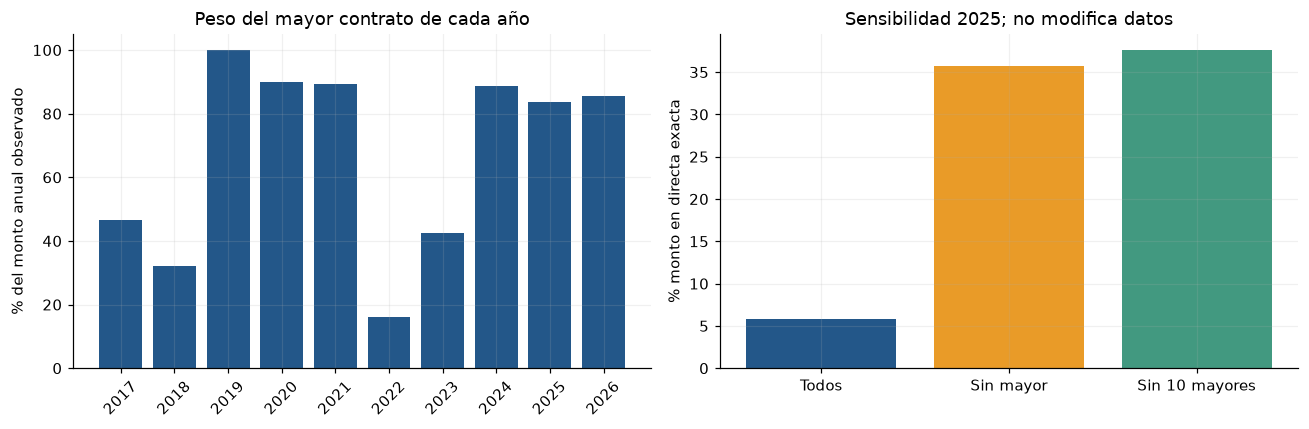

**Conclusión de esta ejecución.** En 2025, un solo contrato representa 83.7% del monto observado. La participación monetaria de directa pasa de 5.8% a 35.7% al apartar únicamente el mayor, como ejercicio de sensibilidad. El contraste conserva el texto de Bronze: coincidencia numérica demuestra procedencia, no corrección económica. Por tanto, las sumas y participaciones monetarias siguientes son provisionales; no deben interpretarse como gasto público verificado. No se corrigió ningún registro sin expediente. “Valor válido” en SQL significa solo finito y no negativo.

In [4]:
# Diagnóstico global de importes y contraste contra CSV original.
extremos_globales=q('''SELECT id_contrato,firma,modalidad,valor,nombre_entidad
 FROM contratos WHERE valor>0 AND isfinite(valor) ORDER BY valor DESC LIMIT 3''')
extremos_anio=q('''SELECT id_contrato,firma,modalidad,valor,nombre_entidad
 FROM contratos WHERE anio=? AND valor>0 AND isfinite(valor) ORDER BY valor DESC LIMIT 3''',[ANIO])
auditar=pd.concat([extremos_globales,extremos_anio]).drop_duplicates('id_contrato')
contraste=[]
for _,r in auditar.iterrows():
    csv=ROOT/'data/bronze/contratos'/('contratos_'+pd.Timestamp(r.firma).strftime('%Y-%m')+'.csv')
    if csv.exists():
        raw=q('SELECT id_contrato,valor_del_contrato FROM read_csv(?,all_varchar=true) WHERE upper(trim(id_contrato))=?',
              [str(csv),r.id_contrato])
        for _,v in raw.iterrows():
            parsed=pd.to_numeric(v.valor_del_contrato,errors='coerce')
            contraste.append({'id_contrato':r.id_contrato,'archivo_Bronze':csv.name,
                'texto_original_Bronze':v.valor_del_contrato,'valor_Silver':r.valor,
                'coincide_numericamente':bool(np.isclose(parsed,r.valor,rtol=1e-12,atol=.01)) if pd.notna(parsed) else False})
    else:
        contraste.append({'id_contrato':r.id_contrato,'archivo_Bronze':csv.name,'texto_original_Bronze':'No disponible',
                         'valor_Silver':r.valor,'coincide_numericamente':None})
display(auditar)
display(pd.DataFrame(contraste))
influencia=q('''WITH r AS(SELECT anio,valor_valido,
 row_number() OVER(PARTITION BY anio ORDER BY valor_valido DESC NULLS LAST,id_contrato) pos
 FROM contratos)
 SELECT anio,sum(valor_valido)/1e12 billones_reportados,
 100.0*max(valor_valido)/nullif(sum(valor_valido),0) pct_mayor_contrato,
 100.0*sum(valor_valido) FILTER(WHERE pos<=10)/nullif(sum(valor_valido),0) pct_mayores_10
 FROM r GROUP BY 1 ORDER BY 1''')
display(influencia)
robustez_monto=q('''WITH r AS(SELECT *,row_number() OVER(ORDER BY valor_valido DESC NULLS LAST,id_contrato) pos
 FROM contratos WHERE anio=?), escenarios AS(SELECT * FROM (VALUES(0),(1),(10)) v(excluir_mayores))
 SELECT excluir_mayores,count(*) contratos,sum(valor_valido)/1e12 billones_observados,
 100.0*coalesce(sum(valor_valido) FILTER(WHERE es_directa),0)/nullif(sum(valor_valido),0) pct_monto_directa
 FROM r CROSS JOIN escenarios WHERE pos>excluir_mayores GROUP BY 1 ORDER BY 1''',[ANIO])
display(robustez_monto)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(influencia.anio.astype(str),influencia.pct_mayor_contrato)
axes[0].set_ylabel('% del monto anual observado');axes[0].set_title('Peso del mayor contrato de cada año');axes[0].tick_params(axis='x',rotation=45)
axes[1].bar(['Todos','Sin mayor','Sin 10 mayores'],robustez_monto.pct_monto_directa,color=['#235789','#e99b28','#429980'])
axes[1].set_ylabel('% monto en directa exacta');axes[1].set_title(f'Sensibilidad {ANIO}; no modifica datos')
plt.tight_layout();plt.show()
influencia_anio=influencia[influencia.anio==ANIO].iloc[0]
conclusion(f'En {ANIO}, un solo contrato representa {influencia_anio.pct_mayor_contrato:.1f}% del monto observado. '
    f'La participación monetaria de directa pasa de {robustez_monto.iloc[0].pct_monto_directa:.1f}% a '
    f'{robustez_monto.iloc[1].pct_monto_directa:.1f}% al apartar únicamente el mayor, como ejercicio de sensibilidad. '
    'El contraste conserva el texto de Bronze: coincidencia numérica demuestra procedencia, no corrección económica. '
    'Por tanto, las sumas y participaciones monetarias siguientes son provisionales; no deben interpretarse como gasto público verificado. '
    'No se corrigió ningún registro sin expediente. “Valor válido” en SQL significa solo finito y no negativo.')


## 3. Evolución anual: contratos e importes

**Referencia:** Tabla 1 y Figura 1, pp. 10–11.

**Por qué:** El tamaño y la adopción de SECOP II cambian con el tiempo. Una caída del último año parcial no demuestra menor actividad.

**Qué y cómo:** Se grafican conteo y monto en paneles separados para evitar dos ejes con escalas arbitrarias. Se muestra total observado y comparación al mismo mes/día del corte. Los montos son nominales, sin deflactar.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,anio,contratos,con_valor,billones,entidades,cobertura
0,2017,22259,22259,68.039,352,año observado
1,2018,142973,142973,"19,649.874",804,año observado
2,2019,142592,142592,"767,785,304.741",920,año observado
3,2020,357251,357251,"115,722.526",979,año observado
4,2021,561581,561581,"493,251.059",1466,año observado
5,2022,710534,710534,123.228,2572,año observado
6,2023,843059,843059,334.828,2876,año observado
7,2024,950670,950670,"7,265.587",2909,año observado
8,2025,1050857,1050857,"1,128.278",3433,año observado
9,2026,860660,860660,675.008,3272,hasta 21/09


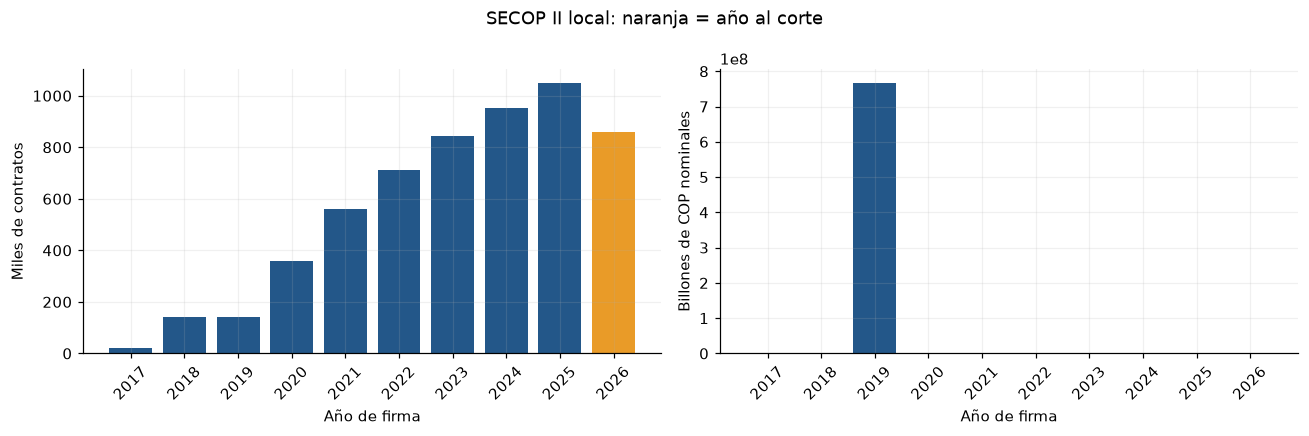

,anio,contratos_periodo_homologo,billones_periodo_homologo
0,2017,10859,65.713
1,2018,103224,"14,186.931"
2,2019,129570,"767,785,295.909"
3,2020,260748,"115,694.165"
4,2021,431226,"480,343.101"
5,2022,545246,81.029
6,2023,689510,292.929
7,2024,730430,"7,155.219"
8,2025,812279,118.141
9,2026,860660,675.008


**Conclusión de esta ejecución.** El máximo conteo anual observado corresponde a 2025. 2026 termina el 21/09: debe compararse con el período homólogo, no con años completos. Incluso así, variaciones de adopción/cobertura y precios impiden atribuir diferencias a decisiones de contratación.

In [5]:
anual=q('''SELECT anio,count(*) contratos,count(valor_valido) con_valor,sum(valor_valido)/1e12 billones,
 count(DISTINCT entidad_id) entidades FROM contratos GROUP BY 1 ORDER BY 1''')
anual['cobertura']=np.where(anual.anio==CORTE.year,'hasta '+CORTE.strftime('%d/%m'),'año observado')
display(anual)
fig,axes=plt.subplots(1,2,figsize=(12,4))
color=['#e99b28' if x==CORTE.year else '#235789' for x in anual.anio]
axes[0].bar(anual.anio.astype(str),anual.contratos/1000,color=color);axes[0].set_ylabel('Miles de contratos')
axes[1].bar(anual.anio.astype(str),anual.billones,color=color);axes[1].set_ylabel('Billones de COP nominales')
for ax in axes: ax.tick_params(axis='x',rotation=45);ax.set_xlabel('Año de firma')
fig.suptitle('SECOP II local: naranja = año al corte');plt.tight_layout();plt.show()
homologo=q(f'''SELECT anio,count(*) contratos,sum(valor_valido)/1e12 billones FROM contratos
 WHERE (month(firma)*100+day(firma))<={CORTE.month*100+CORTE.day} GROUP BY 1 ORDER BY 1''')
display(homologo.rename(columns={'contratos':'contratos_periodo_homologo','billones':'billones_periodo_homologo'}))
conclusion(f'El máximo conteo anual observado corresponde a {int(anual.loc[anual.contratos.idxmax(),"anio"])}. '
    f'{CORTE.year} termina el {CORTE.strftime("%d/%m")}: debe compararse con el período homólogo, no con años completos. '
    'Incluso así, variaciones de adopción/cobertura y precios impiden atribuir diferencias a decisiones de contratación.')

## 4. Modalidades y tipos: frecuencia frente a dinero

**Referencia:** Figura 2, p. 13; Tabla 14, p. 58.

**Por qué:** Una modalidad puede dominar el número de contratos sin dominar el monto. Esto orienta qué comparar dentro de directa.

**Qué y cómo:** Barras ordenadas de porcentajes sobre todas las modalidades del año de comparación. Directa con ofertas y régimen especial se conservan como categorías distintas. Los tipos son los registrados en SECOP II; no se les impone la clasificación del artículo.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,modalidad,n,valor,porcentaje_contratos,porcentaje_valor_observado
0,contratacion directa,802117,"65,744,984,634,459.281",76.330,5.827
1,contratacion regimen especial,155817,"23,421,438,864,384.055",14.828,2.076
2,minima cuantia,49691,"946,300,791,497,880.875",4.729,83.871
3,contratacion directa (con ofertas),10567,"27,894,998,513,096.328",1.006,2.472
4,seleccion abreviada de menor cuantia,9564,"9,296,528,122,795.314",0.910,0.824
5,contratacion regimen especial (con ofertas),8397,"9,828,474,596,580.484",0.799,0.871
6,seleccion abreviada subasta inversa,8194,"9,651,210,831,371.266",0.780,0.855
7,concurso de meritos abierto,2574,"3,200,048,103,418.032",0.245,0.284
8,licitacion publica,2164,"13,722,304,142,972.723",0.206,1.216
9,licitacion publica obra publica,1375,"15,103,635,240,116.422",0.131,1.339


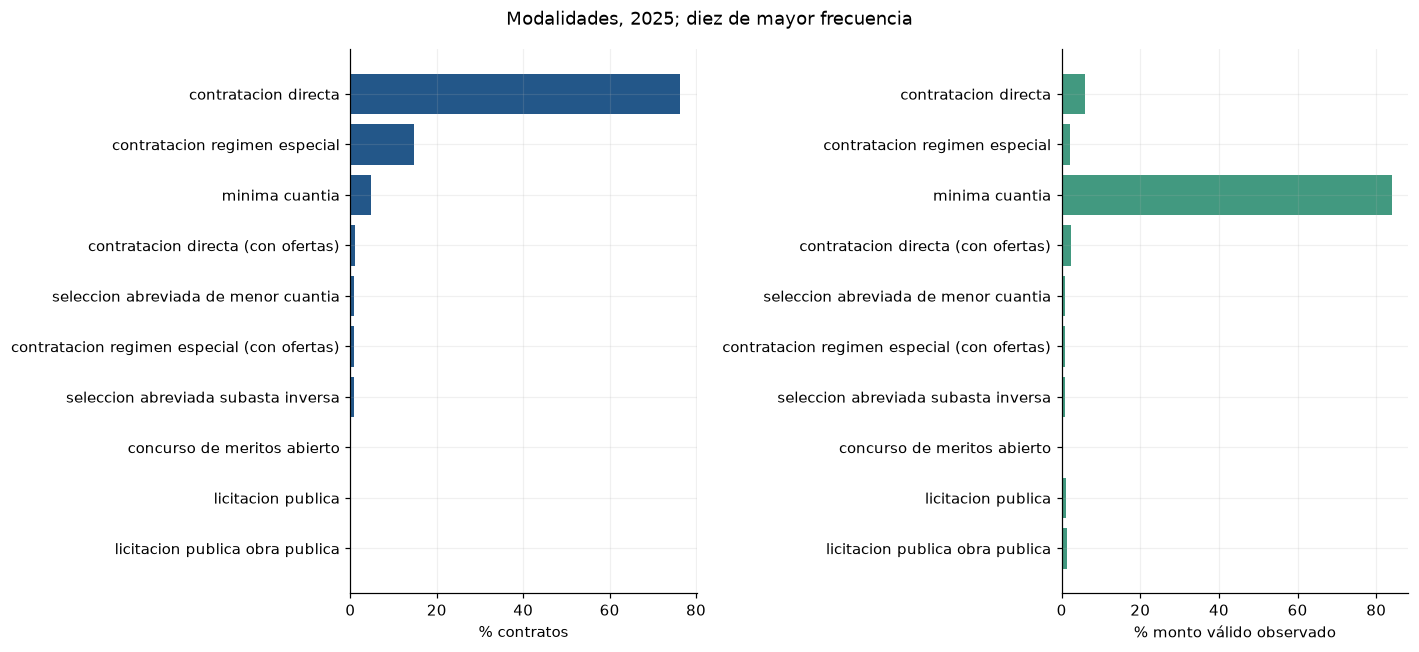

,tipo,n,billones,directos
0,prestacion de servicios,901465,"1,001.572",771133
1,decreto 092 de 2017,42595,8.436,0
2,otro,40461,60.434,18614
3,suministros,23038,13.055,343
4,compraventa,17075,7.891,384
5,obra,9838,23.160,2328
6,arrendamiento de inmuebles,6839,1.260,6839
7,comodato,2219,0.034,2219
8,consultoria,2155,1.367,0
9,seguros,2034,1.348,23


**Conclusión de esta ejecución.** H1: directa exacta representa 76.3% del conteo y 5.8% del monto válido observado en 2025. El mayor contrato pesa 83.7% del total monetario: H1 es sensible a esos importes y no se interpreta sin la sección 2b. Las sumas no son gasto verificado.

In [6]:
modal=q('''SELECT coalesce(modalidad,'sin modalidad') modalidad,count(*) n,sum(valor_valido) valor
 FROM contratos WHERE anio=? GROUP BY 1 ORDER BY n DESC''',[ANIO])
modal['porcentaje_contratos']=100*modal.n/modal.n.sum()
modal['porcentaje_valor_observado']=100*modal.valor/modal.valor.sum()
display(modal)
fig,axes=plt.subplots(1,2,figsize=(13,6))
m=modal.head(10).iloc[::-1]
axes[0].barh(m.modalidad,m.porcentaje_contratos);axes[0].set_xlabel('% contratos')
axes[1].barh(m.modalidad,m.porcentaje_valor_observado,color='#429980');axes[1].set_xlabel('% monto válido observado')
fig.suptitle(f'Modalidades, {ANIO}; diez de mayor frecuencia');plt.tight_layout();plt.show()
tipos=q('''SELECT coalesce(tipo,'sin tipo') tipo,count(*) n,sum(valor_valido)/1e12 billones,
 count(*) FILTER(WHERE es_directa) directos FROM contratos WHERE anio=? GROUP BY 1 ORDER BY n DESC''',[ANIO])
display(tipos)
row=modal[modal.modalidad=='contratacion directa'].iloc[0]
conclusion(f'H1: directa exacta representa {row.porcentaje_contratos:.1f}% del conteo y {row.porcentaje_valor_observado:.1f}% del monto válido observado en {ANIO}. '
    f'El mayor contrato pesa {influencia_anio.pct_mayor_contrato:.1f}% del total monetario: H1 es sensible a esos importes y no se interpreta sin la sección 2b. Las sumas no son gasto verificado.')

## 5. Entidades comparables y clasificación administrativa

**Referencia:** Tabla 5 / Figura 4, pp. 30–33.

**Por qué:** Comparar contratos individuales sobrepondera entidades grandes. Para caracterizar entidades se usa una observación por entidad y año.

**Qué y cómo:** La clasificación se obtiene de orden y centralización. Si un NIT tiene etiquetas contradictorias se marca mixto/sin dato. No se infiere categoría municipal por ciudad o población, ni se clasifica como distrital una entidad nacional localizada en Bogotá.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

**Unidad institucional:** se agrupa por NIT; unidades con el mismo NIT quedan juntas. El nombre mostrado es un ejemplo de los nombres registrados, no un nombre maestro validado. Las etiquetas Nacional/Territorial corresponden a lo reportado y pueden requerir contraste institucional.

In [7]:
sql('''CREATE TEMP TABLE entidades AS SELECT entidad_id,anio,min(nombre_entidad) entidad,
 CASE WHEN count(DISTINCT nivel)=1 AND count(nivel)=count(*) THEN min(nivel) ELSE 'mixto/sin dato' END nivel,
 CASE WHEN count(DISTINCT centralizacion)=1 AND count(centralizacion)=count(*) THEN min(centralizacion) ELSE 'mixto/sin dato' END centralizacion,
 count(*) n,count(valor_valido) n_valor,sum(valor_valido) valor,
 count(*) FILTER(WHERE es_directa) n_cd,sum(valor_valido) FILTER(WHERE es_directa) valor_cd,
 count(*) FILTER(WHERE es_especial) n_re,sum(valor_valido) FILTER(WHERE es_especial) valor_re
 FROM contratos WHERE entidad_id IS NOT NULL GROUP BY 1,2''')
composicion=q('''SELECT nivel,centralizacion,count(*) entidades,sum(n) contratos,sum(valor)/1e12 billones
 FROM entidades WHERE anio=? GROUP BY 1,2 ORDER BY 3 DESC''',[ANIO])
display(composicion)
display(q('''SELECT anio,nivel,sum(valor)/1e12 billones,sum(n) contratos FROM entidades GROUP BY 1,2 ORDER BY 1,2'''))
conclusion(f'La comparación de {ANIO} contiene {fmt(composicion.entidades.sum())} entidades con NIT disponible. '
    'Las categorías municipales 1–6 del artículo no están disponibles. Los contratos sin NIT se conservan en totales generales, '
    'pero se excluyen de agregados por entidad; la tabla de cobertura cuantifica ese límite.')

,nivel,centralizacion,entidades,contratos,billones
0,territorial,centralizada,2230,"441,038.000","1,014.459"
1,nacional,centralizada,549,"167,156.000",43.057
2,territorial,descentralizada,309,"97,832.000",13.488
3,territorial,mixto/sin dato,111,"106,549.000",14.549
4,nacional,descentralizada,83,"21,033.000",5.486
5,nacional,mixto/sin dato,59,"113,346.000",21.132
6,corporacion autonoma,centralizada,46,"6,742.000",1.116
7,mixto/sin dato,centralizada,25,"49,404.000",8.234
8,mixto/sin dato,mixto/sin dato,10,"41,235.000",4.811
9,corporacion autonoma,descentralizada,10,"6,285.000",1.822


,anio,nivel,billones,contratos
0,2017,corporacion autonoma,0.004,103.000
1,2017,mixto/sin dato,0.353,983.000
2,2017,nacional,66.960,"16,712.000"
3,2017,territorial,0.723,"4,461.000"
4,2018,corporacion autonoma,0.143,"2,029.000"
...,...,...,...,...
35,2025,territorial,"1,042.496","645,419.000"
36,2026,corporacion autonoma,1.259,"13,696.000"
37,2026,mixto/sin dato,6.300,"73,617.000"
38,2026,nacional,613.821,"231,115.000"


**Conclusión de esta ejecución.** La comparación de 2025 contiene 3,433 entidades con NIT disponible. Las categorías municipales 1–6 del artículo no están disponibles. Los contratos sin NIT se conservan en totales generales, pero se excluyen de agregados por entidad; la tabla de cobertura cuantifica ese límite.

## 6. Participación de directa: nivel, evolución y casos

**Referencia:** Figuras 6–7 y Tabla 8, pp. 38–43.

**Por qué:** Se necesita el denominador de todas las modalidades para evaluar el peso de directa y separar su evolución de la de régimen especial.

**Qué y cómo:** Boxplots de porcentajes por entidad para el año de comparación, con al menos 30 contratos; el monto exige cobertura monetaria completa. Las series comparan la participación agregada, que pondera por gasto y no equivale a la media simple de entidades.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

**Lectura de ejes:** `pct_cd_n` = porcentaje del número de contratos en directa; `pct_cd_valor` = porcentaje del monto en directa. En las cajas se indica cuántas entidades contribuyen. Unidades y cobertura monetaria son distintas de los conteos.

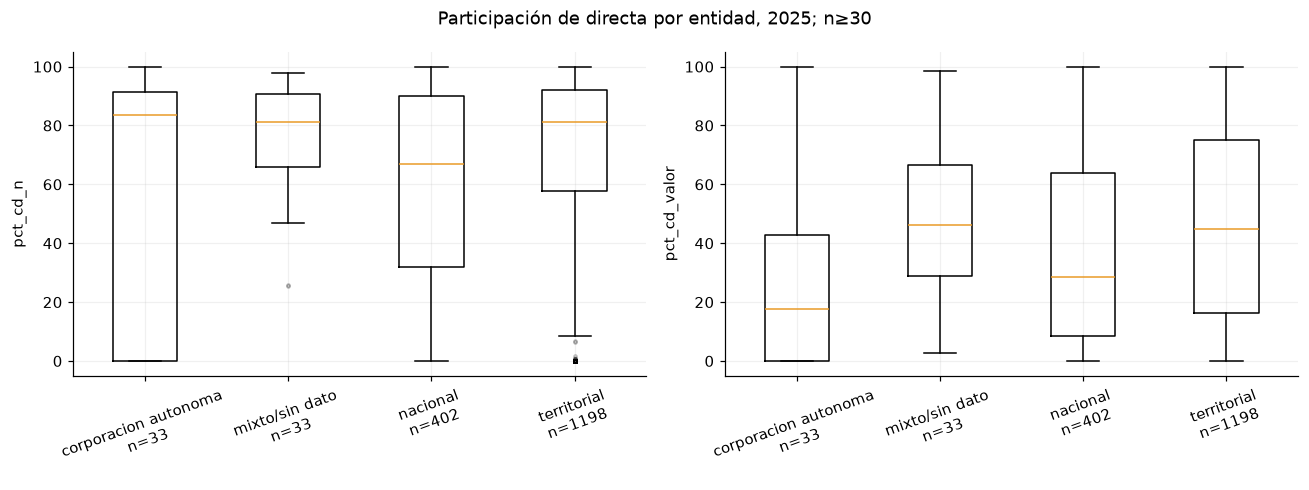

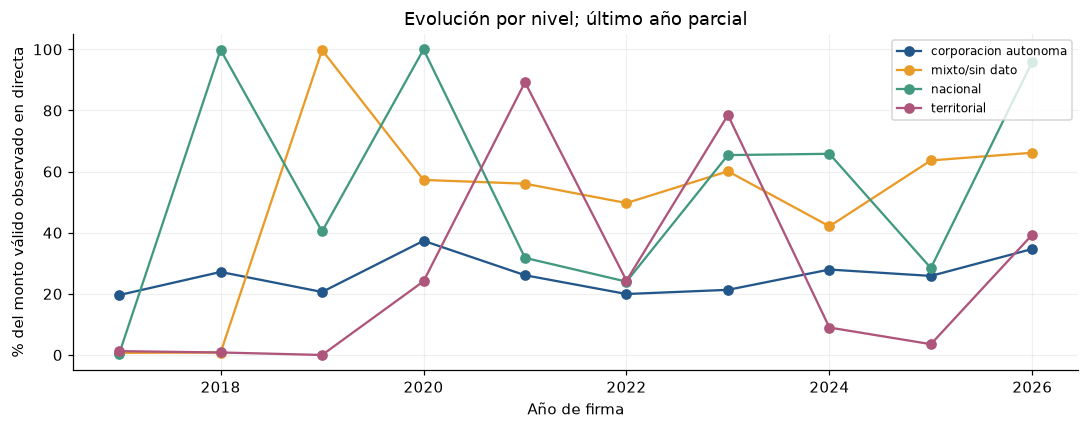

,entidad_id,entidad,nivel,n,pct_cd_n,pct_cd_valor,pct_cd_re_valor
1215,814000385,INSTITUTO MUNICIPAL PARA LA RECREACION Y EL DE...,territorial,312,95.513,0.000,0.000
806,899999239,ICBF REGIONAL AMAZONAS,nacional,24372,73.781,15.003,97.769
247,890905211,CONCEJO MUNICIPAL DE MEDELLIN,territorial,2507,73.873,27.986,33.207
46,899999022,MINISTERIO DE MINAS Y ENERGIA,nacional,2080,92.933,2.647,3.047
941,890900286,ASAMBLEA DEPARTAMENTAL DE ANTIOQUIA,territorial,1516,70.251,41.597,43.684
30,8999990619,(Secretaría Distrital de Integración Social),territorial,23571,97.480,49.154,70.924
832,890399011,CONCEJO DISTRITAL DE SANTIAGO DE CALI,mixto/sin dato,35162,97.949,66.536,75.208
260,899999040,RNEC,nacional,233,58.369,12.086,12.086
820,899999061,.SECRETARÍA DISTRITAL DE SALUD.,mixto/sin dato,26625,93.183,42.170,43.964
32,891800498,GOBERNACIÓN DE BOYACÁ,territorial,4099,73.018,6.414,9.180


**Conclusión de esta ejecución.** En el subconjunto de entidades con al menos 30 contratos, la mediana de directa por conteo es 79.2%, y por monto con cobertura completa 40.2%. Diferencias entre niveles pueden reflejar composición de servicios y tamaño. No se convierten en un componente nuevo del IRCD.

In [8]:
part=q('''SELECT *,100.0*n_cd/n pct_cd_n,
 CASE WHEN n_valor=n AND valor>0 THEN 100.0*coalesce(valor_cd,0)/valor END pct_cd_valor,
 CASE WHEN n_valor=n AND valor>0 THEN 100.0*(coalesce(valor_cd,0)+coalesce(valor_re,0))/valor END pct_cd_re_valor
 FROM entidades WHERE anio=? AND n>=?''',[ANIO,MIN_CONTRATOS])
def box_by(frame,group,columns,title):
    groups=sorted(frame[group].dropna().unique())
    fig,axes=plt.subplots(1,len(columns),figsize=(6*len(columns),4.5),squeeze=False)
    for ax,col in zip(axes.ravel(),columns):
        arrays=[frame.loc[frame[group]==g,col].dropna().to_numpy() for g in groups]
        keep=[(g,a) for g,a in zip(groups,arrays) if len(a)]
        if keep:
            ax.boxplot([a for g,a in keep],tick_labels=[str(g)+'\nn='+str(len(a)) for g,a in keep],
                showfliers=True,flierprops={'markersize':2,'alpha':.25})
            ax.tick_params(axis='x',rotation=20)
        ax.set_ylabel(col)
    fig.suptitle(title);plt.tight_layout();plt.show()
box_by(part,'nivel',['pct_cd_n','pct_cd_valor'],f'Participación de directa por entidad, {ANIO}; n≥{MIN_CONTRATOS}')
serie=q('''SELECT anio,nivel,sum(n_cd)*100.0/sum(n) pct_contratos,
 sum(coalesce(valor_cd,0))*100.0/nullif(sum(valor),0) pct_monto_observado FROM entidades GROUP BY 1,2 ORDER BY 1,2''')
fig,ax=plt.subplots(figsize=(10,4))
for nivel,g in serie.groupby('nivel'): ax.plot(g.anio,g.pct_monto_observado,marker='o',label=nivel)
ax.set_ylabel('% del monto válido observado en directa');ax.set_xlabel('Año de firma');ax.legend(fontsize=8)
ax.set_title('Evolución por nivel; último año parcial');plt.tight_layout();plt.show()
display(part.nlargest(10,'valor')[['entidad_id','entidad','nivel','n','pct_cd_n','pct_cd_valor','pct_cd_re_valor']])
conclusion(f'En el subconjunto de entidades con al menos {MIN_CONTRATOS} contratos, la mediana de directa por conteo es '
    f'{part.pct_cd_n.median():.1f}%, y por monto con cobertura completa {part.pct_cd_valor.median():.1f}%. '
    'Diferencias entre niveles pueden reflejar composición de servicios y tamaño. No se convierten en un componente nuevo del IRCD.')

## 7. Enero y estacionalidad

**Referencia:** Figura 8, p. 41.

**Por qué:** La concentración al inicio del año puede reflejar calendario presupuestal, renovaciones u otras prácticas; describirla ayuda a formular hipótesis.

**Qué y cómo:** Se replica el monto directo de enero, acompañado del porcentaje anual solo en años completos y un mapa mes–año de conteos. Meses posteriores al corte quedan ausentes, no cero. No se atribuye causalidad electoral ni se evalúa cumplimiento de normas.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,anio,n,billones,pct_contratos_enero,pct_valor_enero
0,2018,32929,"2,889.842",35.725,34.093
1,2019,39152,"36,801.789",45.704,99.992
2,2020,35568,"104,251.372",12.986,90.132
3,2021,57912,3.070,12.815,0.001
4,2022,282590,12.732,49.927,41.083
5,2023,101060,5.589,15.503,2.283
6,2024,89021,5.841,12.115,0.807
7,2025,126340,7.907,15.751,12.027
8,2026,458801,26.073,NaN,NaN


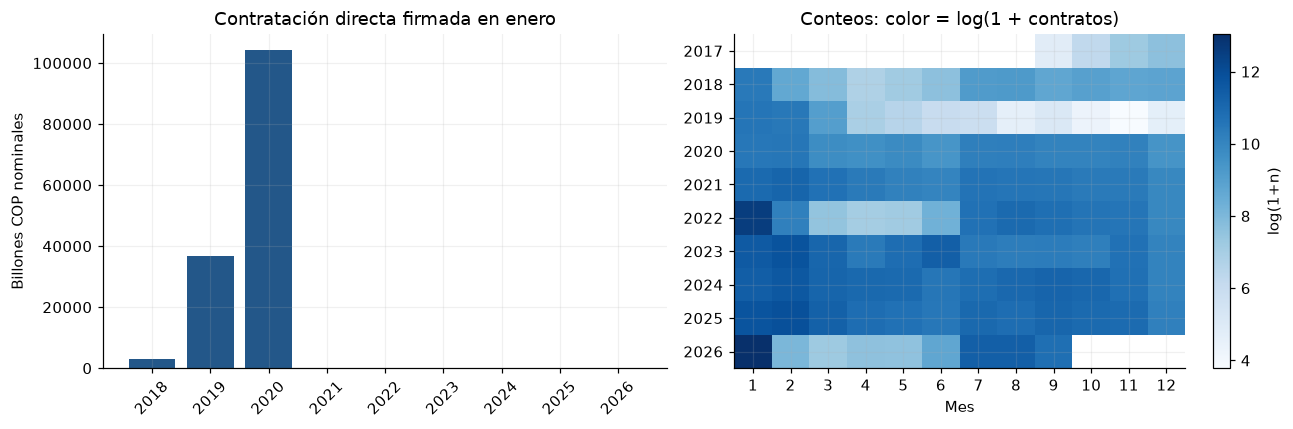

**Conclusión de esta ejecución.** H4: en años completos, enero reúne una mediana de 15.6% de los contratos directos. La referencia uniforme 1/12 es descriptiva, no una expectativa normativa. La estacionalidad por sí sola no explica su causa.

In [9]:
meses=q('SELECT anio,mes,count(*) n,sum(valor_valido)/1e12 billones FROM directa GROUP BY 1,2 ORDER BY 1,2')
enero=meses[meses.mes==1].merge(meses.groupby('anio',as_index=False).agg(total_n=('n','sum'),total_billones=('billones','sum')),on='anio')
enero['pct_contratos_enero']=100*enero.n/enero.total_n
enero['pct_valor_enero']=100*enero.billones/enero.total_billones
if (CORTE.month,CORTE.day)!=(12,31): enero.loc[enero.anio==CORTE.year,['pct_contratos_enero','pct_valor_enero']]=np.nan
display(enero[['anio','n','billones','pct_contratos_enero','pct_valor_enero']])
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(enero.anio.astype(str),enero.billones);axes[0].set_ylabel('Billones COP nominales');axes[0].set_title('Contratación directa firmada en enero')
axes[0].tick_params(axis='x',rotation=45)
heat=meses.pivot(index='anio',columns='mes',values='n').reindex(columns=range(1,13))
im=axes[1].imshow(np.log1p(heat),aspect='auto',cmap='Blues')
axes[1].set_xticks(range(12),range(1,13));axes[1].set_yticks(range(len(heat)),heat.index)
axes[1].set_xlabel('Mes');axes[1].set_title('Conteos: color = log(1 + contratos)');fig.colorbar(im,ax=axes[1],label='log(1+n)')
plt.tight_layout();plt.show()
conclusion(f'H4: en años completos, enero reúne una mediana de {enero.pct_contratos_enero.median():.1f}% de los contratos directos. '
    'La referencia uniforme 1/12 es descriptiva, no una expectativa normativa. La estacionalidad por sí sola no explica su causa.')

## 8. Concentración: participaciones, HHI y cuatro mayores

**Referencia:** Tabla 7 indicadores 7/8/14/15, pp. 34–35; Tabla 10, p. 46.

**Por qué:** El dinero puede concentrarse en unos pocos contratos mientras el conteo se distribuye. HHI y CR4 permiten explorar esa diferencia.

**Qué y cómo:** Para directa, por entidad/año/proveedor se calcula participación por conteo y por monto. HHI=Σparticipación² y CR4=suma de las cuatro mayores participaciones, ambas en 0–1. Son descripciones de concentración, no componentes adicionales del IRCD. Si falta identidad o valor, el HHI correspondiente queda nulo.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

**Lectura de ejes:** `hhi_n` es concentración por conteo; `hhi_valor` es concentración monetaria. Ambos van de 0 a 1; 1 significa que un solo proveedor concentra todo el universo calculable de la entidad/año.

hhi_n                    hhi_valor                     \
                     count  mean median   std     count  mean median   std   
nivel                                                                        
corporacion autonoma    23 0.013  0.005 0.015        23 0.075  0.044 0.069   
mixto/sin dato          30 0.010  0.009 0.009        30 0.111  0.041 0.181   
nacional               276 0.010  0.006 0.010       276 0.079  0.026 0.149   
territorial            929 0.014  0.010 0.017       929 0.092  0.047 0.125   

                     cr4_n                    cr4_valor                     
                     count  mean median   std     count  mean median   std  
nivel                                                                       
corporacion autonoma    23 0.074  0.038 0.082        23 0.359  0.309 0.196  
mixto/sin dato          30 0.072  0.058 0.060        30 0.382  0.322 0.232  
nacional               276 0.063  0.044 0.060       276 0.289  0.200 0.248  
territorial            929 0.092  0.075 0.075       929 0.366  0.336 0.215

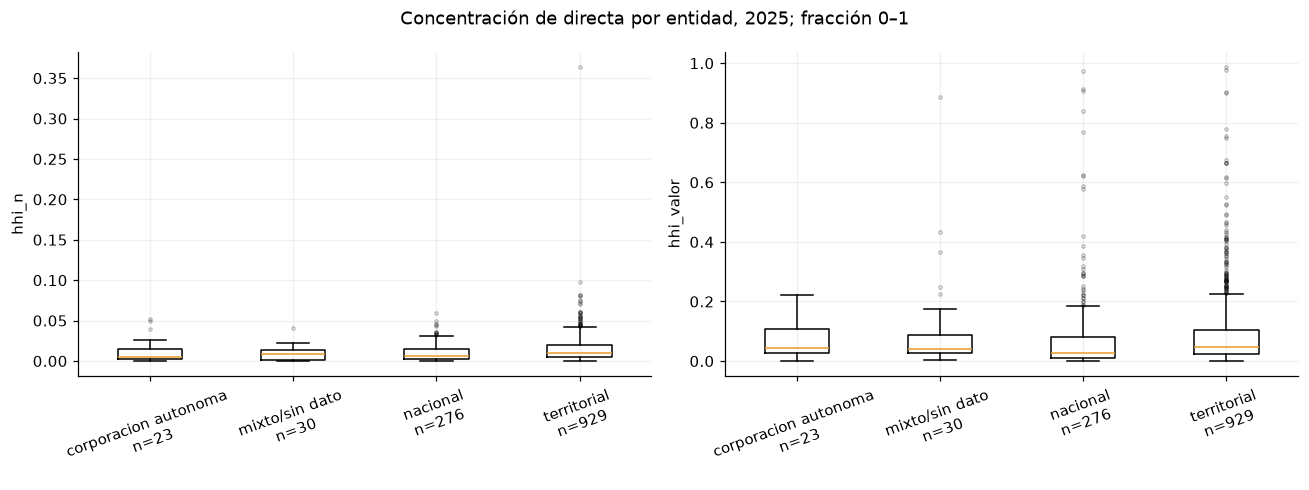

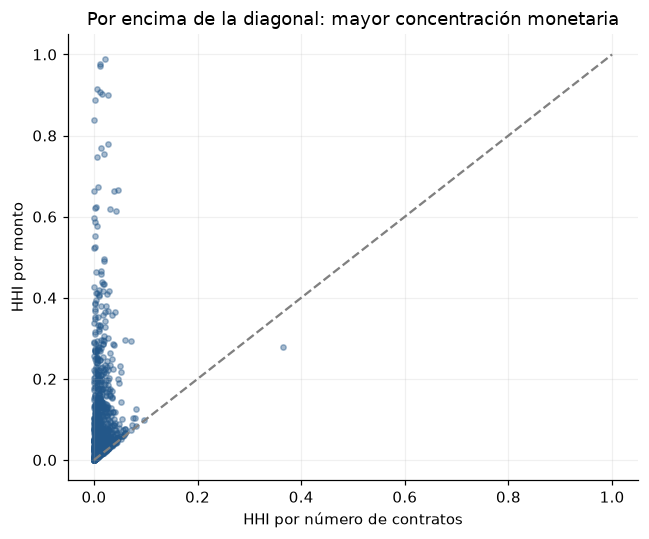

**Conclusión de esta ejecución.** H2: en 1,258 entidades con ambas métricas, 99.3% presenta HHI monetario mayor que HHI por conteo. Esto orienta revisión de contratos grandes, no demuestra que exista un valor indebido. No se calculó el índice de dominancia del artículo porque no se ha fijado una equivalencia de fórmula/normalización.

In [10]:
sql('''CREATE TEMP TABLE pares AS SELECT entidad_id,anio,proveedor_id,count(*) n,sum(valor_valido) monto
 FROM directa WHERE entidad_id IS NOT NULL AND proveedor_id IS NOT NULL GROUP BY 1,2,3''')
sql('''CREATE TEMP TABLE totales_cd AS SELECT entidad_id,anio,count(*) n_total,
 count(*) FILTER(WHERE proveedor_id IS NULL) n_sin_proveedor,count(valor_valido) n_valor,sum(valor_valido) monto_total
 FROM directa WHERE entidad_id IS NOT NULL GROUP BY 1,2''')
sql('''CREATE TEMP TABLE participaciones AS SELECT p.*,t.* EXCLUDE(entidad_id,anio),
 p.n*1.0/t.n_total s_n,p.monto/nullif(t.monto_total,0) s_valor,
 row_number() OVER(PARTITION BY p.entidad_id,p.anio ORDER BY p.n DESC,p.proveedor_id) rn_n,
 row_number() OVER(PARTITION BY p.entidad_id,p.anio ORDER BY p.monto DESC NULLS LAST,p.proveedor_id) rn_valor
 FROM pares p JOIN totales_cd t USING(entidad_id,anio)''')
sql('''CREATE TEMP TABLE concentracion AS SELECT p.entidad_id,p.anio,
 max(p.n_total) n_directos,max(p.monto_total) monto_directo,count(*) proveedores,
 CASE WHEN max(p.n_sin_proveedor)=0 THEN sum(s_n*s_n) END hhi_n,
 CASE WHEN max(p.n_sin_proveedor)=0 AND max(p.n_valor)=max(p.n_total) AND max(p.monto_total)>0 THEN sum(s_valor*s_valor) END hhi_valor,
 CASE WHEN max(p.n_sin_proveedor)=0 THEN sum(s_n) FILTER(WHERE rn_n<=4) END cr4_n,
 CASE WHEN max(p.n_sin_proveedor)=0 AND max(p.n_valor)=max(p.n_total) AND max(p.monto_total)>0 THEN sum(s_valor) FILTER(WHERE rn_valor<=4) END cr4_valor
 FROM participaciones p GROUP BY 1,2''')
hh=q('''SELECT c.*,e.nivel,e.centralizacion,e.entidad FROM concentracion c JOIN entidades e USING(entidad_id,anio)
 WHERE c.anio=? AND c.n_directos>=?''',[ANIO,MIN_CONTRATOS])
display(hh.groupby('nivel')[['hhi_n','hhi_valor','cr4_n','cr4_valor']].agg(['count','mean','median','std']).round(3))
box_by(hh,'nivel',['hhi_n','hhi_valor'],f'Concentración de directa por entidad, {ANIO}; fracción 0–1')
valid_hh=hh.dropna(subset=['hhi_n','hhi_valor'])
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(valid_hh.hhi_n,valid_hh.hhi_valor,s=12,alpha=.4);ax.plot([0,1],[0,1],'--',color='gray')
ax.set_xlabel('HHI por número de contratos');ax.set_ylabel('HHI por monto');ax.set_title('Por encima de la diagonal: mayor concentración monetaria')
plt.tight_layout();plt.show()
conclusion(f'H2: en {len(valid_hh):,} entidades con ambas métricas, {100*(valid_hh.hhi_valor>valid_hh.hhi_n).mean():.1f}% '
    'presenta HHI monetario mayor que HHI por conteo. Esto orienta revisión de contratos grandes, no demuestra que exista un valor indebido. '
    'No se calculó el índice de dominancia del artículo porque no se ha fijado una equivalencia de fórmula/normalización.')

## 9. Cuatro proveedores principales y distribución acumulada

**Referencia:** Tabla 9, pp. 44–45.

**Por qué:** Un ranking nacional y la concentración dentro de una entidad responden preguntas distintas. Se muestran ambos niveles sin confundirlos.

**Qué y cómo:** Se identifican los cuatro proveedores de mayor monto observado de contratación directa por año y se usa un alias hash. No se suman contratos de integrantes de consorcios ni se multiplica el monto al cruzar con grupos. El gráfico acumulado del año elegido muestra cuánto concentra la cabeza de la distribución.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,anio,puesto,proveedor_alias,n,miles_millones_COP
0,2017,1,P-b53b3224ddd0,7,99.346
1,2017,2,P-8ece695657cc,1,30.703
2,2017,3,P-399f739e6a86,1,4.217
3,2017,4,P-b48806d9b9db,1,2.300
4,2018,1,P-479c730838ab,2,"3,247,560.007"
...,...,...,...,...,...
35,2025,4,P-c634f377a689,20,"1,028.062"
36,2026,1,P-53340ab55e0c,2,"577,152.594"
37,2026,2,P-0ea43f87a7e8,2,"1,269.398"
38,2026,3,P-db4a7342945d,7,466.920


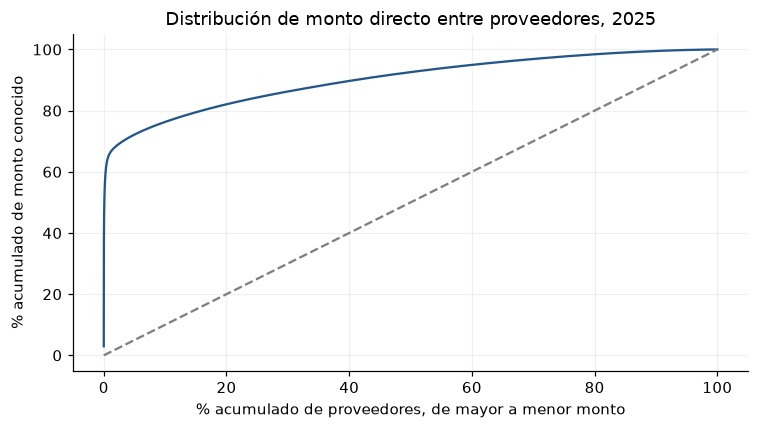

**Conclusión de esta ejecución.** El 1% superior de proveedores identificados reúne 66.1% del monto válido observado en 2025. Este total nacional no sustituye C, cuyo denominador es la entidad y el segmento. Las sumas son montos reportados del snapshot, no pagos ejecutados.

In [11]:
top=q('''WITH p AS(SELECT anio,proveedor_id,count(*) n,sum(valor_valido) monto FROM directa
 WHERE proveedor_id IS NOT NULL GROUP BY 1,2),r AS(SELECT *,row_number() OVER(PARTITION BY anio ORDER BY monto DESC NULLS LAST,proveedor_id) puesto FROM p)
 SELECT anio,puesto,'P-'||substr(sha256(proveedor_id),1,12) proveedor_alias,n,monto/1e9 miles_millones_COP
 FROM r WHERE puesto<=4 ORDER BY anio,puesto''')
display(top)
prov=q('''SELECT proveedor_id,sum(valor_valido) monto FROM directa WHERE anio=? AND proveedor_id IS NOT NULL
 GROUP BY 1 HAVING sum(valor_valido)>0 ORDER BY monto DESC''',[ANIO])
x=100*np.arange(1,len(prov)+1)/max(len(prov),1);y=100*prov.monto.cumsum()/prov.monto.sum()
fig,ax=plt.subplots(figsize=(7,4));ax.plot(x,y);ax.plot([0,100],[0,100],'--',color='gray')
ax.set_xlabel('% acumulado de proveedores, de mayor a menor monto');ax.set_ylabel('% acumulado de monto conocido')
ax.set_title(f'Distribución de monto directo entre proveedores, {ANIO}');plt.tight_layout();plt.show()
top1_share=float(prov.head(max(1,int(np.ceil(len(prov)*.01)))).monto.sum()/prov.monto.sum()*100)
conclusion(f'El 1% superior de proveedores identificados reúne {top1_share:.1f}% del monto válido observado en {ANIO}. '
    'Este total nacional no sustituye C, cuyo denominador es la entidad y el segmento. Las sumas son montos reportados del snapshot, no pagos ejecutados.')

## 10. Comparar entidades de gasto similar

**Referencia:** Figura 11 / Tabla 13, pp. 55–57.

**Por qué:** Con pocos contratos es fácil obtener concentración alta. El estudio advierte que entidades pequeñas pueden distorsionar comparaciones.

**Qué y cómo:** Se forman cuantiles de gasto directo observado del mismo año, con empates conservados; si se repiten cortes hay menos de diez grupos. Se exige al menos 30 contratos. Se compara HHI dentro de esos grupos; no se inventan deciles de riesgo o presupuesto.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,entidades,min_COP,max_COP,mediana_hhi,mediana_contratos
grupo_gasto,,,,,
1,126,"235,256,543.000","1,183,695,319.800",0.043,52.000
2,126,"1,188,532,036.980","1,958,497,693.400",0.031,71.500
3,126,"1,972,020,223.000","2,878,844,572.880",0.028,108.000
4,125,"2,879,175,121.000","4,243,203,400.000",0.034,133.000
5,126,"4,245,730,926.000","6,146,000,144.240",0.030,177.500
6,126,"6,154,698,287.760","9,731,236,345.140",0.046,237.500
7,125,"9,743,559,199.000","16,107,113,452.000",0.048,354.000
8,126,"16,115,788,928.350","31,877,600,987.420",0.088,410.000
9,126,"31,975,635,491.910","100,385,544,127.000",0.057,699.000


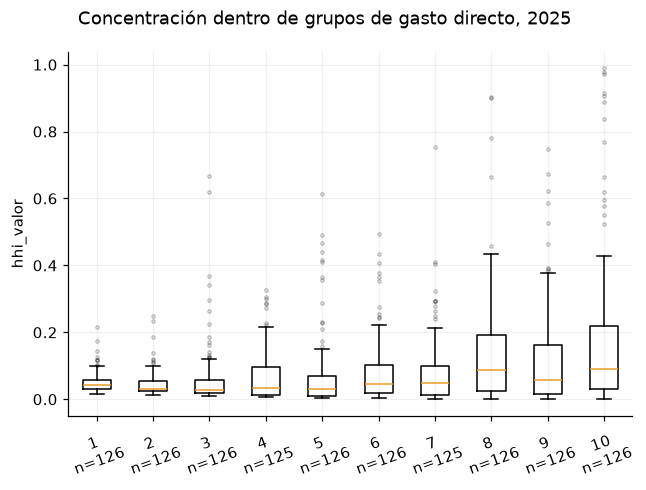

,entidad_id,entidad,nivel,n_directos,monto_directo,hhi_valor,extremo
15,899999034,CENTRO DE COMERCIO Y SERVICIOS - SENA REGIONAL...,nacional,41832,"1,614,924,400,750.010",0.000,menor HHI
160,899999027,DANE - DIRECCION TERRITORIAL CENTRO,nacional,6594,"186,726,399,760.700",0.000,menor HHI
3,900948953,AGENCIA NACIONAL DE TIERRAS - ANT,nacional,11243,"491,004,203,365.280",0.000,menor HHI
22,800214750,INSTITUCIÓN UNIVERSITARIA ITM,nacional,19491,"392,793,668,434.000",0.001,menor HHI
867,860061099,IDRD - ENTIDAD OFICIAL.,territorial,3747,"197,442,168,585.000",0.001,menor HHI
1115,800030988,sutamarchan,territorial,92,"288,759,102,925.000",0.989,mayor HHI
220,800103657,MUNICIPIO DE LA SALINA,territorial,135,"182,412,107,943.810",0.977,mayor HHI
410,899999238,CORPORACIÓN AUTÓNOMA REGIONAL PARA EL DESARROL...,nacional,153,"243,242,533,855.000",0.972,mayor HHI
875,830041314,DIRECCION DE SANIDAD DE LA POLICIA NACIONAL - ...,nacional,210,"226,409,573,149.900",0.914,mayor HHI
456,800029660,ALCALDIA MUNICIPAL DE MIRAFLORES BOYACA,nacional,171,"129,263,757,932.390",0.908,mayor HHI


**Conclusión de esta ejecución.** H3: entre 1,258 entidades elegibles se formaron 10 grupos de gasto. Los extremos mostrados pertenecen al mismo grupo de mayor monto y son casos para contrastar, no un ranking de integridad. Persisten diferencias de misión, tipo contractual y mercado proveedor.

In [12]:
dec=hh.dropna(subset=['monto_directo','hhi_valor']).copy()
dec=dec[dec.monto_directo>0]
dec['grupo_gasto']=pd.qcut(dec.monto_directo,q=min(10,len(dec)),labels=False,duplicates='drop')+1
display(dec.groupby('grupo_gasto').agg(entidades=('entidad_id','size'),min_COP=('monto_directo','min'),max_COP=('monto_directo','max'),
    mediana_hhi=('hhi_valor','median'),mediana_contratos=('n_directos','median')))
box_by(dec,'grupo_gasto',['hhi_valor'],f'Concentración dentro de grupos de gasto directo, {ANIO}')
mayor=dec[dec.grupo_gasto==dec.grupo_gasto.max()]
display(pd.concat([mayor.nsmallest(5,'hhi_valor').assign(extremo='menor HHI'),mayor.nlargest(5,'hhi_valor').assign(extremo='mayor HHI')])
    [['entidad_id','entidad','nivel','n_directos','monto_directo','hhi_valor','extremo']])
conclusion(f'H3: entre {len(dec):,} entidades elegibles se formaron {dec.grupo_gasto.nunique()} grupos de gasto. '
    'Los extremos mostrados pertenecen al mismo grupo de mayor monto y son casos para contrastar, no un ranking de integridad. '
    'Persisten diferencias de misión, tipo contractual y mercado proveedor.')

## 11. Tipos de contrato y categorías comparables

**Referencia:** Tablas 14–15, pp. 58–59.

**Por qué:** Mezclar tipos puede ocultar patrones. El estudio distingue categorías de compra; SECOP II permite otra segmentación que debe declararse.

**Qué y cómo:** Se cruzan año y tipo registrado con conteo y monto directo. El prefijo de dos dígitos se extrae únicamente de códigos que contienen ocho dígitos; no se asignan nombres de categorías sin diccionario validado.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,anio,tipo,contratos,billones,mediana_COP
72,2025,prestacion de servicios,771133,32.075,"20,000,000.000"
73,2025,otro,18614,22.988,"100,000,000.000"
74,2025,arrendamiento de inmuebles,6839,1.260,"25,640,841.000"
75,2025,obra,2328,2.086,"78,796,499.000"
76,2025,comodato,2219,0.034,0.000
77,2025,compraventa,384,0.360,"110,200,000.000"
78,2025,suministros,343,0.410,"79,846,000.000"
79,2025,operaciones de credito publico,158,6.418,"7,839,470,954.000"
80,2025,servicios financieros,74,0.110,0.000
81,2025,seguros,23,0.001,"21,378,492.000"


,prefijo_UNSPSC,contratos,billones
0,80,676816,27.047
1,93,33592,7.440
2,85,19539,4.497
3,86,17418,3.682
4,81,12251,3.916
5,72,7337,4.449
6,77,5908,0.630
7,84,4367,6.242
8,90,3764,0.557
9,82,3263,0.464


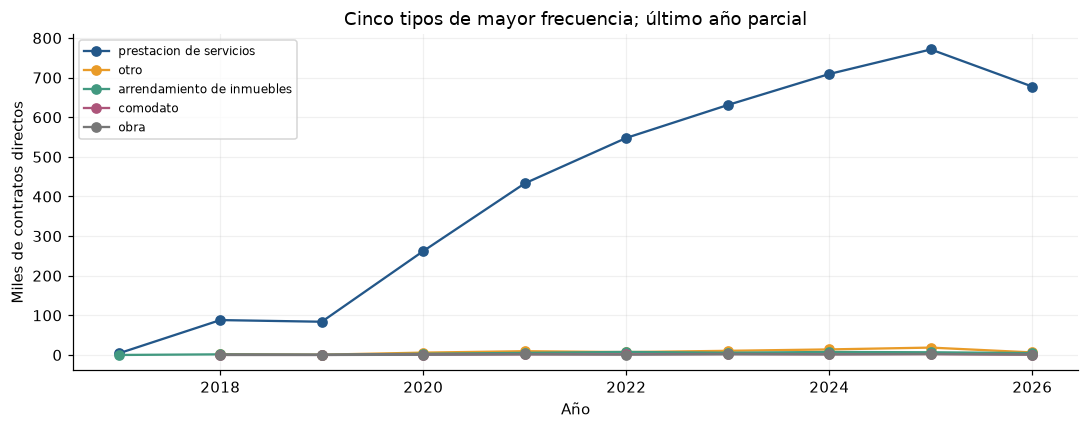

**Conclusión de esta ejecución.** En 2025, el tipo más frecuente dentro de directa es «prestacion de servicios» con 771,133 contratos. Esta composición justifica mantener los servicios en el caso de control, aunque el artículo excluya algunos. Prefijo UNSPSC y tipo no bastan para acreditar igual experiencia, dedicación o complejidad.

In [13]:
tipo_anio=q('''SELECT anio,coalesce(tipo,'sin tipo') tipo,count(*) contratos,sum(valor_valido)/1e12 billones,
 median(valor_valido) mediana_COP FROM directa GROUP BY 1,2 ORDER BY 1,3 DESC''')
display(tipo_anio[tipo_anio.anio==ANIO])
cat=q('''SELECT nullif(substr(regexp_extract(categoria,'([0-9]{8})',1),1,2),'') prefijo_UNSPSC,
 count(*) contratos,sum(valor_valido)/1e12 billones FROM directa WHERE anio=? GROUP BY 1 ORDER BY 2 DESC''',[ANIO])
display(cat.head(15))
fig,ax=plt.subplots(figsize=(10,4))
dominantes=tipo_anio.groupby('tipo').contratos.sum().nlargest(5).index
for t in dominantes:
    g=tipo_anio[tipo_anio.tipo==t];ax.plot(g.anio,g.contratos/1000,marker='o',label=t)
ax.legend(fontsize=8);ax.set_ylabel('Miles de contratos directos');ax.set_xlabel('Año');ax.set_title('Cinco tipos de mayor frecuencia; último año parcial')
plt.tight_layout();plt.show()
top_tipo=tipo_anio[tipo_anio.anio==ANIO].sort_values('contratos',ascending=False).iloc[0]
conclusion(f'En {ANIO}, el tipo más frecuente dentro de directa es «{top_tipo.tipo}» con {fmt(top_tipo.contratos)} contratos. '
    'Esta composición justifica mantener los servicios en el caso de control, aunque el artículo excluya algunos. '
    'Prefijo UNSPSC y tipo no bastan para acreditar igual experiencia, dedicación o complejidad.')

## 12. Recurrencia: ventana real y relación con concentración

**Referencia:** Extensión del caso de control; relacionada con la diversidad y concentración de pp. 34–46.

**Por qué:** Contar por año calendario omite contratos cercanos a diciembre/enero. También interesa saber si C y R duplican parte de la señal.

**Qué y cómo:** Se calcula una ventana inclusiva de 365 días por entidad/proveedor, sin contratos futuros. Al faltar causal en el snapshot, esta es recurrencia descriptiva sin segmentar, no score R. La correlación usa una observación por par/año y solo ventanas con cobertura completa; se estratifica por volumen de la entidad.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,r365,contratos
0,1,"279,108.000"
1,2,"283,572.000"
2,3,"167,736.000"
3,4,"45,263.000"
4,5,"14,782.000"
5,6,"4,827.000"
6,7,"1,610.000"
7,8,930.000
8,9,581.000
9,10,451.000


,estrato,pares,spearman
0,100-999,173143,0.273
1,1000+,362849,0.214
2,30-99,17211,0.348
3,<30,4640,0.148


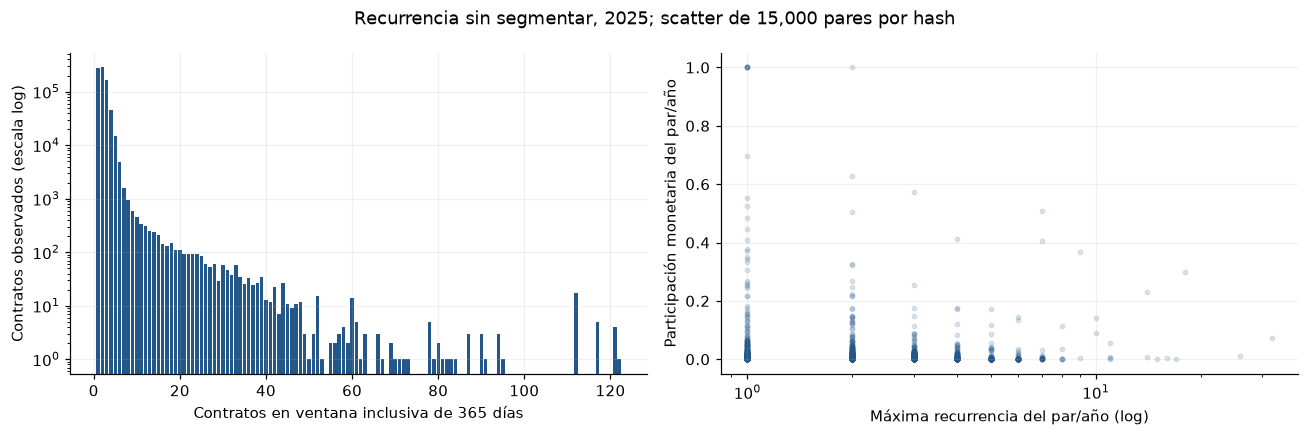

**Conclusión de esta ejecución.** H5: 65.2% de los contratos con ventana completa tiene al menos dos contratos del par en 365 días. La correlación de rangos entre participación monetaria y recurrencia máxima es 0.107. Parte de la asociación es mecánica: ambas métricas usan contratos del mismo proveedor. No prueba favoritismo; hay que contrastar causal y servicio antes de calibrar el IRCD.

In [14]:
sql('''CREATE TEMP TABLE dias AS SELECT entidad_id,proveedor_id,firma,count(*) n
 FROM directa WHERE entidad_id IS NOT NULL AND proveedor_id IS NOT NULL GROUP BY 1,2,3''')
sql('''CREATE TEMP TABLE movil AS SELECT *,sum(n) OVER(PARTITION BY entidad_id,proveedor_id ORDER BY firma
 RANGE BETWEEN INTERVAL 365 DAYS PRECEDING AND CURRENT ROW)::BIGINT r365 FROM dias''')
dist_r=q(f'''SELECT r365,sum(n) contratos FROM movil WHERE year(firma)={ANIO}
 AND firma-INTERVAL 365 DAYS>=DATE {L(INICIO.date())} GROUP BY 1 ORDER BY 1''')
display(dist_r.head(25))
sql(f'''CREATE TEMP TABLE relacion AS SELECT p.*,m.max_r365,
 CASE WHEN p.n_total<30 THEN '<30' WHEN p.n_total<100 THEN '30-99' WHEN p.n_total<1000 THEN '100-999' ELSE '1000+' END estrato
 FROM participaciones p JOIN (SELECT entidad_id,proveedor_id,year(firma) anio,max(r365) max_r365
 FROM movil WHERE firma-INTERVAL 365 DAYS>=DATE {L(INICIO.date())} GROUP BY 1,2,3) m
 USING(entidad_id,proveedor_id,anio)
 WHERE p.anio={ANIO} AND p.n_sin_proveedor=0 AND p.n_valor=p.n_total AND p.monto_total>0''')
rel=q('SELECT entidad_id,proveedor_id,s_valor,max_r365,estrato FROM relacion')
spearman=rel[['s_valor','max_r365']].rank().corr().iloc[0,1]
res=[]
for st,g in rel.groupby('estrato'):
    res.append({'estrato':st,'pares':len(g),'spearman':g[['s_valor','max_r365']].rank().corr().iloc[0,1] if len(g)>1 else np.nan})
display(pd.DataFrame(res))
sample=q(f'SELECT s_valor,max_r365,estrato FROM relacion ORDER BY hash(entidad_id,proveedor_id) LIMIT {MUESTRA_SCATTER}')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(dist_r.r365,dist_r.contratos);axes[0].set_yscale('log');axes[0].set_xlabel('Contratos en ventana inclusiva de 365 días');axes[0].set_ylabel('Contratos observados (escala log)')
axes[1].scatter(sample.max_r365,sample.s_valor,s=8,alpha=.15);axes[1].set_xscale('log');axes[1].set_xlabel('Máxima recurrencia del par/año (log)');axes[1].set_ylabel('Participación monetaria del par/año')
fig.suptitle(f'Recurrencia sin segmentar, {ANIO}; scatter de {len(sample):,} pares por hash');plt.tight_layout();plt.show()
pct_repite=100*dist_r.loc[dist_r.r365>=2,'contratos'].sum()/dist_r.contratos.sum()
conclusion(f'H5: {pct_repite:.1f}% de los contratos con ventana completa tiene al menos dos contratos del par en 365 días. '
    f'La correlación de rangos entre participación monetaria y recurrencia máxima es {spearman:.3f}. '
    'Parte de la asociación es mecánica: ambas métricas usan contratos del mismo proveedor. No prueba favoritismo; '
    'hay que contrastar causal y servicio antes de calibrar el IRCD.')

## 13. Valores extremos y comparabilidad monetaria

**Referencia:** Revisión de importes extraordinarios, p. 16; extensión A del caso actual.

**Por qué:** El artículo contrasta extremos con documentos. El EDA puede localizarlos y evaluar asimetría, pero no declarar errores o sobreprecios.

**Qué y cómo:** Percentiles e histogramas de log10 del importe positivo; scatter de duración e importe sin eliminar extremos. La mensualización se presenta solo como sensibilidad aritmética, no como remuneración validada ni score A. Se deja constancia de negativos, ceros y fechas imposibles en cobertura.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,tipo,n,n_valor,mediana,p90,p95,p99,maximo
0,prestacion de servicios,771133,771133,"20,000,000.000","60,203,000.000","85,000,000.000","166,235,963.200","286,723,822,000.000"
1,otro,18614,18614,"100,000,000.000","1,628,016,657.900","3,596,817,377.150","16,319,043,048.170","1,615,266,971,115.000"
2,arrendamiento de inmuebles,6839,6839,"25,640,841.000","285,932,428.800","539,703,387.600","2,152,706,107.200","239,856,000,000.000"
3,obra,2328,2328,"78,796,499.000","717,727,859.300","1,803,018,878.864","8,187,212,964.680","893,052,000,000.000"
4,comodato,2219,2219,0.000,"6,900,130.032","61,267,169.700","247,574,411.620","5,193,412,258.000"
5,compraventa,384,384,"110,200,000.000","1,984,663,825.100","5,077,037,272.450","14,593,574,985.380","21,375,395,000.000"
6,suministros,343,343,"79,846,000.000","1,115,041,600.000","2,920,691,548.900","10,291,501,020.000","216,418,540,000.000"
7,operaciones de credito publico,158,158,"7,839,470,954.000","139,500,000,000.000","200,000,000,000.000","424,430,669,618.111","600,000,000,000.000"
8,servicios financieros,74,74,0.000,"2,425,150,445.700","8,519,326,654.300","27,778,127,985.908","39,825,541,137.440"
9,seguros,23,23,"21,378,492.000","76,552,670.600","154,721,008.600","192,691,448.740","201,028,037.000"


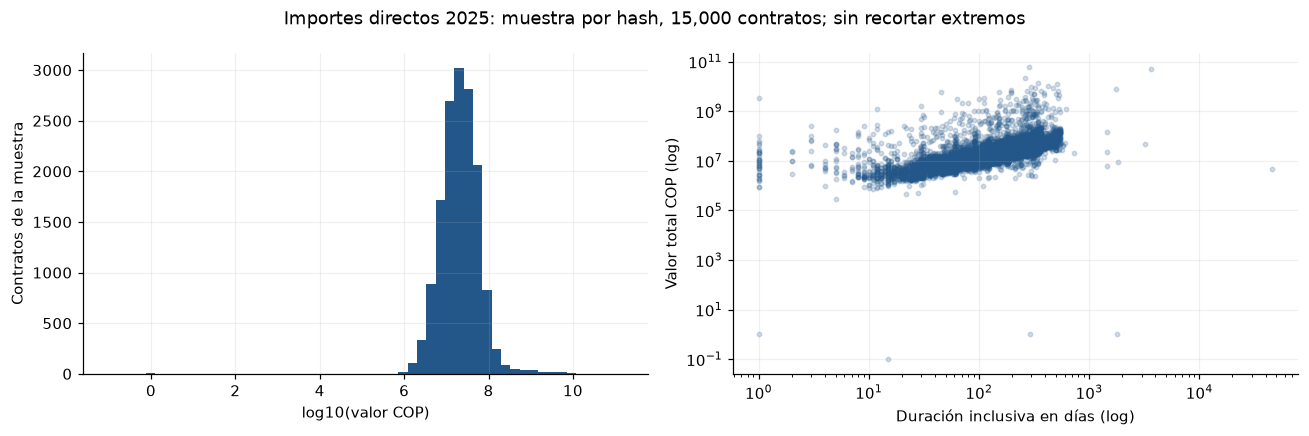

,id_contrato,nombre_entidad,tipo,miles_millones_COP,duracion_dias
0,CO1.PCCNTR.8739217,MINSALUD,otro,"1,615.267",3289
1,CO1.PCCNTR.8750509,ALCALDÍA DISTRITAL DE SANTA MARTA,obra,893.052,4284
2,CO1.PCCNTR.8565538,MINTRABAJO NIVEL CENTRAL*/,otro,770.096,40
3,CO1.PCCNTR.7868084,SANTIAGO DE CALI DISTRITO ESPECIAL - DEPARTAME...,operaciones de credito publico,600.000,5114
4,CO1.PCCNTR.7455669,GOBERNACIÓN DE RISARALDA**,otro,540.775,1417
5,CO1.PCCNTR.8618650,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,operaciones de credito publico,503.211,3647
6,CO1.PCCNTR.7772981,SANTIAGO DE CALI DISTRITO ESPECIAL - DEPARTAME...,operaciones de credito publico,365.000,4403
7,CO1.PCCNTR.7862082,DEPARTAMENTO DE ANTIOQUIA//,otro,358.016,945
8,CO1.PCCNTR.8424777,DISTRITO ESPECIAL DE CIENCIA TECNOLOGIA E INNO...,operaciones de credito publico,296.539,3645
9,CO1.PCCNTR.8396157,sutamarchan,prestacion de servicios,286.724,250


,candidatos,mediana_equivalente,p95_equivalente
0,766937,"4,150,909.091","10,973,747.905"


**Conclusión de esta ejecución.** H6: 766,937 contratos de servicios permiten la división aritmética por duración, pero eso no acredita pagos mensuales o servicios homogéneos. Las referencias por causal/perfil no pueden sustituirse por un percentil global. Los diez importes mostrados requieren revisar el expediente, su unidad y el monto original; no fueron corregidos ni eliminados.

In [15]:
stats=q('''SELECT tipo,count(*) n,count(valor_valido) n_valor,median(valor_valido) mediana,
 quantile_cont(valor_valido,.9) p90,quantile_cont(valor_valido,.95) p95,quantile_cont(valor_valido,.99) p99,max(valor_valido) maximo
 FROM directa WHERE anio=? GROUP BY 1 ORDER BY 2 DESC''',[ANIO])
display(stats)
scatter=q(f'''SELECT id_contrato,tipo,valor,duracion_dias FROM directa WHERE anio={ANIO} AND valor>0 AND isfinite(valor)
 ORDER BY hash(id_contrato) LIMIT {MUESTRA_SCATTER}''')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(np.log10(scatter.valor),bins=55);axes[0].set_xlabel('log10(valor COP)');axes[0].set_ylabel('Contratos de la muestra')
valid=scatter[scatter.duracion_dias>0]
axes[1].scatter(valid.duracion_dias,valid.valor,s=8,alpha=.2);axes[1].set_xscale('log');axes[1].set_yscale('log')
axes[1].set_xlabel('Duración inclusiva en días (log)');axes[1].set_ylabel('Valor total COP (log)')
fig.suptitle(f'Importes directos {ANIO}: muestra por hash, {len(scatter):,} contratos; sin recortar extremos');plt.tight_layout();plt.show()
extremos=q('''SELECT id_contrato,nombre_entidad,tipo,valor/1e9 miles_millones_COP,duracion_dias
 FROM directa WHERE anio=? AND valor>0 AND isfinite(valor) ORDER BY valor DESC LIMIT 10''',[ANIO])
display(extremos)
mensual=q('''SELECT count(*) candidatos,median(valor*30.44/duracion_dias) mediana_equivalente,
 quantile_cont(valor*30.44/duracion_dias,.95) p95_equivalente
 FROM directa WHERE anio=? AND tipo='prestacion de servicios' AND valor>0 AND isfinite(valor)
 AND duracion_dias BETWEEN 1 AND 1096''',[ANIO])
display(mensual)
conclusion(f'H6: {fmt(mensual.iloc[0].candidatos)} contratos de servicios permiten la división aritmética por duración, '
    'pero eso no acredita pagos mensuales o servicios homogéneos. Las referencias por causal/perfil no pueden sustituirse '
    'por un percentil global. Los diez importes mostrados requieren revisar el expediente, su unidad y el monto original; no fueron corregidos ni eliminados.')

## 14. Sensibilidad: pocos contratos y servicios largos

**Referencia:** Advertencia sobre entidades pequeñas, p. 56; exclusión de servicios, p. 16.

**Por qué:** Una conclusión útil debe resistir decisiones de selección razonables. El umbral de 30 y excluir servicios largos cambian la población.

**Qué y cómo:** Se comparan medianas de HHI con mínimos 10, 30 y 100, siempre mostrando tamaño. Por separado se calcula el efecto de excluir candidatos de servicios largos sobre conteos y montos; no se aplica ese filtro al ETL ni se afirma replicar exactamente el filtro de Fedesarrollo.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

In [16]:
all_hh=q('SELECT * FROM concentracion WHERE anio=?',[ANIO])
sens=pd.DataFrame([{'mínimo_contratos':k,'entidades':int((all_hh.n_directos>=k).sum()),
    'con_hhi_monto':int(all_hh.loc[all_hh.n_directos>=k,'hhi_valor'].notna().sum()),
    'mediana_hhi_n':all_hh.loc[all_hh.n_directos>=k,'hhi_n'].median(),
    'mediana_hhi_valor':all_hh.loc[all_hh.n_directos>=k,'hhi_valor'].median()} for k in [10,30,100]])
display(sens)
serv=q('''SELECT count(*) n,sum(valor_valido) monto,
 count(*) FILTER(WHERE tipo='prestacion de servicios' AND fin>inicio+INTERVAL 6 MONTHS) candidatos,
 sum(valor_valido) FILTER(WHERE tipo='prestacion de servicios' AND fin>inicio+INTERVAL 6 MONTHS) monto_candidatos
 FROM directa WHERE anio=?''',[ANIO]).iloc[0]
display(pd.DataFrame([{'escenario':'Directa conservada','contratos':serv.n,'billones':serv.monto/1e12},
 {'escenario':'Sin candidatos de servicios >6 meses; sensibilidad','contratos':serv.n-serv.candidatos,'billones':(serv.monto-serv.monto_candidatos)/1e12}]))
conclusion(f'Excluir esos candidatos retiraría {100*serv.candidatos/serv.n:.1f}% del conteo directo y '
    f'{100*serv.monto_candidatos/serv.monto:.1f}% del monto observado de {ANIO}. '
    'Por eso se documenta la diferencia frente al artículo y se mantienen en el caso de control. '
    'La estabilidad o cambio de medianas con el mínimo de contratos se observa en la tabla, no se presume.')

,mínimo_contratos,entidades,con_hhi_monto,mediana_hhi_n,mediana_hhi_valor
0,10,1467,1467,0.011,0.053
1,30,1258,1258,0.009,0.043
2,100,901,901,0.006,0.040


,escenario,contratos,billones
0,Directa conservada,"802,117.000",65.745
1,Sin candidatos de servicios >6 meses; sensibil...,"509,319.000",43.818


**Conclusión de esta ejecución.** Excluir esos candidatos retiraría 36.5% del conteo directo y 33.4% del monto observado de 2025. Por eso se documenta la diferencia frente al artículo y se mantienen en el caso de control. La estabilidad o cambio de medianas con el mínimo de contratos se observa en la tabla, no se presume.

## 15. Cambios anuales en un conjunto estable de entidades

**Referencia:** Precauciones sobre adopción de SECOP II, pp. 36–37.

**Por qué:** Un incremento agregado puede provenir de entidades que empiezan a reportar, no de cambios dentro de las mismas entidades.

**Qué y cómo:** Se compara la participación de directa entre el año de análisis y el anterior usando entidades presentes en ambos. Se informan diferencias en puntos porcentuales sobre entidades con cobertura monetaria completa en ambos años. Es una comparación descriptiva pareada, no un efecto causal.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

,entidades,media_cambio_pp,mediana_cambio_pp
nivel,,,
corporacion autonoma,45,-2.983,0.000
mixto/sin dato,29,8.393,0.362
nacional,612,-0.238,0.000
territorial,1890,1.307,0.000


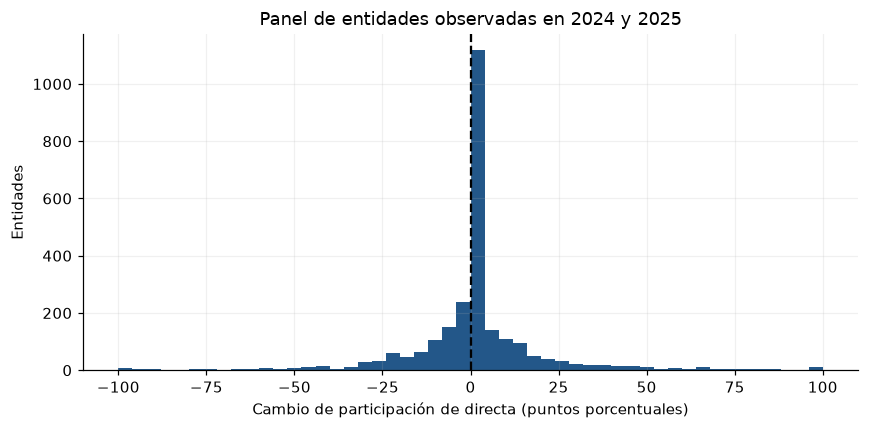

**Conclusión de esta ejecución.** En 2,576 entidades comparables, la mediana del cambio es 0.00 puntos porcentuales. Los resultados del conjunto estable pueden diferir de los totales. Se necesita separar composición contractual y cobertura antes de explicar el cambio.

In [17]:
panel=q('''SELECT a.entidad_id,a.entidad,a.nivel,a.n n_actual,b.n n_previo,
 100.0*coalesce(a.valor_cd,0)/nullif(a.valor,0) pct_actual,
 100.0*coalesce(b.valor_cd,0)/nullif(b.valor,0) pct_previo
 FROM entidades a JOIN entidades b ON a.entidad_id=b.entidad_id AND a.anio=b.anio+1
 WHERE a.anio=? AND a.n_valor=a.n AND b.n_valor=b.n AND a.valor>0 AND b.valor>0''',[ANIO])
panel['cambio_pp']=panel.pct_actual-panel.pct_previo
display(panel.groupby('nivel').agg(entidades=('entidad_id','size'),media_cambio_pp=('cambio_pp','mean'),mediana_cambio_pp=('cambio_pp','median')))
fig,ax=plt.subplots(figsize=(8,4));ax.hist(panel.cambio_pp,bins=50);ax.axvline(0,color='black',ls='--')
ax.set_xlabel('Cambio de participación de directa (puntos porcentuales)');ax.set_ylabel('Entidades');ax.set_title(f'Panel de entidades observadas en {ANIO-1} y {ANIO}')
plt.tight_layout();plt.show()
conclusion(f'En {len(panel):,} entidades comparables, la mediana del cambio es {panel.cambio_pp.median():.2f} puntos porcentuales. '
    'Los resultados del conjunto estable pueden diferir de los totales. Se necesita separar composición contractual y cobertura antes de explicar el cambio.')

## 16. Relación con el IRCD y límites de réplica

**Referencia:** Índice del estudio: pp. 28–29; alcance actual C/R/A.

**Por qué:** El índice del documento y el IRCD tienen distintas unidades, componentes y escalas. No deben intercambiarse ni reconstruirse con indicadores disponibles a medias.

**Qué y cómo:** Si existe Gold contractual se muestra su cobertura y fecha, sin recalcularlo. Si no existe, se declara. La comparación del artículo sobre transparencia, sanciones, oferentes y categorías municipales no se inventa a partir de sustitutos.

La conclusión calculada aparece después de la tabla o gráfico; se limita al universo y cobertura indicados.

In [18]:
gold=ROOT/'data/gold/contratos_control/contratos.parquet'
if gold.exists():
    con.from_parquet(str(gold)).create_view('gold_actual')
    display(q('SELECT fecha_corte,version_parametros,estado_indice,count(*) contratos FROM gold_actual GROUP BY 1,2,3'))
    conclusion('Gold está disponible. Sus fechas y universo deben coincidir antes de cruzarlo con este EDA; no se reconstruyó ni alteró su índice.')
else:
    conclusion('No existe todavía Gold contractual. Este notebook ejecutó el EDA desde Silver; no fabricó scores C/R/A ni un IRCD completo.')
display(pd.DataFrame([
 {'elemento':'Índice original de 32 indicadores','estado':'No replicado','motivo':'Fuentes y alcance distintos; no cambiar IRCD'},
 {'elemento':'Publicación de documentos y sanciones','estado':'No disponible','motivo':'No hay bases documentales/sanciones en el proyecto'},
 {'elemento':'Indicadores de oferentes','estado':'Fuera del caso de directa','motivo':'Son procesos competitivos; no añadir cuarto componente'},
 {'elemento':'Categorías municipales 1–6','estado':'No disponible','motivo':'No inferir a partir del nombre o ubicación'},
 {'elemento':'Año original de cargue vs firma','estado':'No disponible','motivo':'Última actualización no equivale a publicación original'},
 {'elemento':'Valores a precios constantes','estado':'No calculado','motivo':'No se incorporó una serie de deflactores'},
 {'elemento':'Causal, persona natural y objeto','estado':'Según cobertura mostrada','motivo':'Requieren nueva extracción cuando faltan'},
 {'elemento':'Acuerdos entre participantes de consorcios','estado':'No calculado','motivo':'No asignar todo el contrato a cada integrante'}]))

,fecha_corte,version_parametros,estado_indice,contratos
0,2026-09-21,ircd-1.0,incompleto,4353720


**Conclusión de esta ejecución.** Gold está disponible. Sus fechas y universo deben coincidir antes de cruzarlo con este EDA; no se reconstruyó ni alteró su índice.

,elemento,estado,motivo
0,Índice original de 32 indicadores,No replicado,Fuentes y alcance distintos; no cambiar IRCD
1,Publicación de documentos y sanciones,No disponible,No hay bases documentales/sanciones en el proy...
2,Indicadores de oferentes,Fuera del caso de directa,Son procesos competitivos; no añadir cuarto co...
3,Categorías municipales 1–6,No disponible,No inferir a partir del nombre o ubicación
4,Año original de cargue vs firma,No disponible,Última actualización no equivale a publicación...
5,Valores a precios constantes,No calculado,No se incorporó una serie de deflactores
6,"Causal, persona natural y objeto",Según cobertura mostrada,Requieren nueva extracción cuando faltan
7,Acuerdos entre participantes de consorcios,No calculado,No asignar todo el contrato a cada integrante


## 17. Síntesis y siguiente revisión

La siguiente celda resume hallazgos calculados, sin extrapolarlos a toda la contratación pública colombiana. Los patrones orientan revisión y no establecen irregularidades. Ninguna conclusión del documento se copia como si fuera resultado de los datos actuales.

In [19]:
hallazgos=pd.DataFrame([
 {'hipótesis':'H1: conteo y monto de directa difieren','evidencia':f'{row.porcentaje_contratos:.1f}% conteo / {row.porcentaje_valor_observado:.1f}% monto; sin mayor: {robustez_monto.iloc[1].pct_monto_directa:.1f}% monto', 'siguiente_paso':'Verificar importes extremos antes de conclusiones monetarias'},
 {'hipótesis':'H2: concentración monetaria difiere del conteo','evidencia':f'{100*(valid_hh.hhi_valor>valid_hh.hhi_n).mean():.1f}% de entidades con HHI monto mayor','siguiente_paso':'Examinar contratos grandes dentro de segmentos comparables'},
 {'hipótesis':'H3: escala afecta la lectura','evidencia':f'Mediana HHI monto: mínimo 10 = {sens.iloc[0].mediana_hhi_valor:.3f}; mínimo 100 = {sens.iloc[2].mediana_hhi_valor:.3f}','siguiente_paso':'Comparar gasto, misión y número de contratos similares'},
 {'hipótesis':'H4: enero concentra actividad','evidencia':f'Mediana {enero.pct_contratos_enero.median():.1f}% del conteo en enero, años completos','siguiente_paso':'Revisar calendario de renovaciones; no inferir efecto electoral'},
 {'hipótesis':'H5: C y R comparten señal','evidencia':f'Spearman descriptivo por par/año = {spearman:.3f}','siguiente_paso':'Evaluar dentro de causal/tipo y revisar doble contabilización'},
 {'hipótesis':'H6: mensualizar no garantiza comparabilidad','evidencia':f'{fmt(mensual.iloc[0].candidatos)} candidatos aritméticos; remuneración no verificada','siguiente_paso':'Validar objeto/perfil antes de habilitar A'}])
display(hallazgos)
estado_final=[(str(p),p.stat().st_size,p.stat().st_mtime_ns) for p in files]
assert estado_final==estado_archivos,'Silver cambió durante el EDA: vuelva a ejecutar con snapshot estable'
con.close();scratch.cleanup()
conclusion('Lectura terminada con inventario Silver estable. Todos los resultados se conservan en las salidas de este notebook. '
    'No se actualizaron tablas PostgreSQL, archivos de datos ni parámetros del IRCD. Para reproducir, ejecutar todas las celdas en orden; '
    'el año comparado y el corte están definidos al inicio.')

,hipótesis,evidencia,siguiente_paso
0,H1: conteo y monto de directa difieren,76.3% conteo / 5.8% monto; sin mayor: 35.7% monto,Verificar importes extremos antes de conclusio...
1,H2: concentración monetaria difiere del conteo,99.3% de entidades con HHI monto mayor,Examinar contratos grandes dentro de segmentos...
2,H3: escala afecta la lectura,Mediana HHI monto: mínimo 10 = 0.053; mínimo 1...,"Comparar gasto, misión y número de contratos s..."
3,H4: enero concentra actividad,"Mediana 15.6% del conteo en enero, años completos",Revisar calendario de renovaciones; no inferir...
4,H5: C y R comparten señal,Spearman descriptivo por par/año = 0.107,Evaluar dentro de causal/tipo y revisar doble ...
5,H6: mensualizar no garantiza comparabilidad,"766,937 candidatos aritméticos; remuneración n...",Validar objeto/perfil antes de habilitar A


**Conclusión de esta ejecución.** Lectura terminada con inventario Silver estable. Todos los resultados se conservan en las salidas de este notebook. No se actualizaron tablas PostgreSQL, archivos de datos ni parámetros del IRCD. Para reproducir, ejecutar todas las celdas en orden; el año comparado y el corte están definidos al inicio.